# Stream B - Clinical Malignancy Prediction

## Setup


In [ ]:
# ── Cell 1: Install Dependencies ──────────────────────────────────────────────
!pip install -q catboost xgboost lightgbm boruta shap optuna imbalanced-learn openpyxl
print("All packages installed")

All packages installed


In [ ]:
# ── Cell 2: Imports & Global Config ───────────────────────────────────────────
import os, time, random, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path

# ── Sklearn ────────────────────────────────────────────────────────────────────
from sklearn.model_selection        import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing          import StandardScaler, RobustScaler, MinMaxScaler, PowerTransformer
from sklearn.experimental           import enable_iterative_imputer
from sklearn.impute                 import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.feature_selection      import RFE, SelectFromModel, mutual_info_classif, chi2, SelectKBest
from sklearn.linear_model           import LogisticRegression, Lasso
from sklearn.discriminant_analysis  import LinearDiscriminantAnalysis
from sklearn.neighbors              import KNeighborsClassifier
from sklearn.svm                    import SVC
from sklearn.naive_bayes            import GaussianNB
from sklearn.tree                   import DecisionTreeClassifier
from sklearn.ensemble               import RandomForestClassifier
from sklearn.neural_network         import MLPClassifier
from sklearn.metrics                import (accuracy_score, precision_score, recall_score,
                                            f1_score, roc_auc_score, confusion_matrix,
                                            classification_report, roc_curve,
                                            precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.manifold               import TSNE
from sklearn.pipeline               import Pipeline

# ── Boosting ───────────────────────────────────────────────────────────────────
from catboost   import CatBoostClassifier
from xgboost    import XGBClassifier
from lightgbm   import LGBMClassifier

# ── Feature Selection ──────────────────────────────────────────────────────────
from boruta     import BorutaPy

# ── SHAP & Explainability ──────────────────────────────────────────────────────
import shap

# ── Imbalanced Learning ────────────────────────────────────────────────────────
from imblearn.over_sampling import SMOTE

# ── Optuna ─────────────────────────────────────────────────────────────────────
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ── Global Style ───────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi'      : 150,
    'axes.spines.top' : False,
    'axes.spines.right': False,
    'font.family'     : 'DejaVu Sans',
})
PALETTE = {'Cancer': '#E84040', 'Benign': '#4A90D9'}

# ── Dataset Path ───────────────────────────────────────────────────────────────
# Google Colab: upload via Files panel or mount Drive
# DATA_PATH = '/content/drive/MyDrive/YOUR_PATH/Supplementary data 1.xlsx'
DATA_PATH = '/content/Supplementary data 1.xlsx'   # ← change if needed

# ── Label Mapping ──────────────────────────────────────────────────────────────
# TYPE: 1 = Ovarian Cancer, 0 = Benign
LABEL_MAP = {1: 'Cancer', 0: 'Benign'}

print(" Imports complete")
print(f"   Seed : {SEED}")
print(f"   Data : {DATA_PATH}")

 Imports complete
   Seed : 42
   Data : /content/Supplementary data 1.xlsx


##  Cell 3: Exploratory Data Analysis (EDA)
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- Dataset overview & class distribution
- Missing values analysis
- Key biomarker distributions (CA125, HE4, Age, CEA, AFP, CA19-9)
- Boxplots: Cancer vs Benign
- Feature correlation heatmap
- t-SNE 2D projection of the full feature space


In [ ]:
# ── Cell 3: Load Data & EDA ────────────────────────────────────────────────────

# ── 3.1 Load ───────────────────────────────────────────────────────────────────
df_raw = pd.read_excel(DATA_PATH)
df = df_raw.copy()

# Add readable label column
df['Label'] = df['TYPE'].map(LABEL_MAP)

print("=" * 55)
print("  DATASET OVERVIEW")
print("=" * 55)
print(f"  Rows       : {df.shape[0]}")
print(f"  Features   : {df.shape[1] - 2}  (excl. TYPE & Label)")
print(f"  Cancer     : {(df.TYPE == 1).sum()}")
print(f"  Benign     : {(df.TYPE == 0).sum()}")
print(f"  Missing    : {df.drop(columns=['TYPE','Label']).isnull().sum().sum()} total cells")
print("=" * 55)
print(df.head(3))

  DATASET OVERVIEW
  Rows       : 349
  Features   : 50  (excl. TYPE & Label)
  Cancer     : 178
  Benign     : 171
  Missing    : 544 total cells
   SUBJECT_ID      AFP     AG  Age   ALB   ALP   ALT   AST  BASO#  BASO%  ...  \
0           1   3.58\t  19.36   47  45.4  56.0  11.0  24.0   0.01    0.3  ...   
1           2  34.24\t  23.98   61  39.9  95.0   9.0  13.0   0.02    0.3  ...   
2           3   1.50\t  18.40   39  45.4  77.0   9.0  18.0   0.03    0.6  ...   

    PCT   PDW  PHOS  PLT   RBC   RDW  TBIL    TP     UA   Label  
0  0.09  13.4  1.46   74  2.64  13.7   5.5  73.9  396.4  Benign  
1  0.30  11.2  1.09  304  4.89  12.7   6.8  72.0  119.2  Benign  
2  0.13  15.2  0.97  112  4.62  12.0  14.8  77.9  209.2  Benign  

[3 rows x 52 columns]


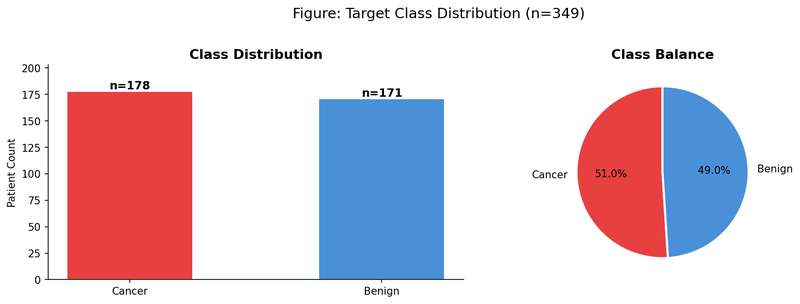

Saved: fig_class_distribution.png


In [ ]:
# ── 3.2 Class Distribution ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
counts = df['Label'].value_counts()
bars = axes[0].bar(counts.index, counts.values,
                   color=[PALETTE[l] for l in counts.index],
                   edgecolor='white', width=0.5)
axes[0].set_title('Class Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Patient Count')
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                 f'n={val}', ha='center', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, counts.max() + 25)

# Pie chart
axes[1].pie(counts.values, labels=counts.index,
            colors=[PALETTE[l] for l in counts.index],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Balance', fontsize=13, fontweight='bold')

plt.suptitle('Figure: Target Class Distribution (n=349)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('fig_class_distribution.png', bbox_inches='tight')
plt.show()
print("Saved: fig_class_distribution.png")

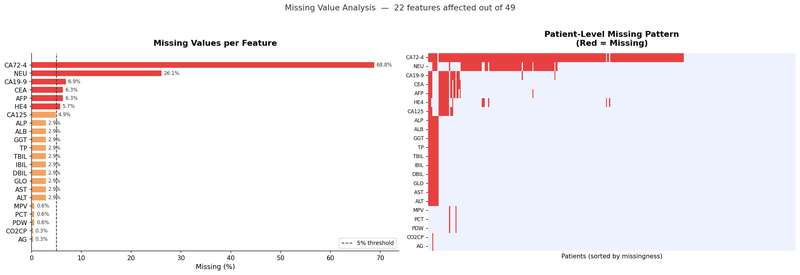

 Saved: fig_missing_values.png


In [ ]:
# ── 3.3 Missing Values Heatmap (REDONE) ───────────────────────────────────────
feature_cols = [c for c in df.columns if c not in ['SUBJECT_ID', 'TYPE', 'Label']]
missing_pct = (df[feature_cols].isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_features = missing_pct[missing_pct > 0]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), facecolor='white')

# ── Left: Sorted horizontal bar chart ─────────────────────────────────────────
colors = ['#E84040' if v > 5 else '#F4A261' for v in missing_features.values]
axes[0].barh(missing_features.index[::-1], missing_features.values[::-1],
             color=colors[::-1], edgecolor='none', height=0.7)
axes[0].axvline(5, color='#333333', linestyle='--', linewidth=1.2,
                label='5% threshold')
axes[0].set_xlabel('Missing (%)', fontsize=11)
axes[0].set_title('Missing Values per Feature', fontsize=13, fontweight='bold', pad=12)
axes[0].legend(fontsize=9)
axes[0].set_xlim(0, missing_features.max() + 5)
for spine in ['top', 'right']:
    axes[0].spines[spine].set_visible(False)

# Annotate bars
for i, (val, name) in enumerate(zip(missing_features.values[::-1],
                                     missing_features.index[::-1])):
    axes[0].text(val + 0.5, i, f'{val:.1f}%', va='center', fontsize=8, color='#333333')

# ── Right: Clean patient-level heatmap (only missing features) ────────────────
missing_df = df[missing_features.index].isnull().astype(int)

# Sort patients by total missing count for visual pattern
missing_df = missing_df.loc[missing_df.sum(axis=1).sort_values(ascending=False).index]

sns.heatmap(missing_df.T,
            cmap=['#EEF2FF', '#E84040'],
            cbar=False,
            ax=axes[1],
            linewidths=0,
            xticklabels=False,
            yticklabels=True)
axes[1].set_title('Patient-Level Missing Pattern\n(Red = Missing)',
                   fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Patients (sorted by missingness)', fontsize=10)
axes[1].set_ylabel('')
axes[1].tick_params(axis='y', labelsize=8)

plt.suptitle(f'Missing Value Analysis  -  {len(missing_features)} features affected out of {len(feature_cols)}',
             fontsize=13, y=1.02, color='#333333')
plt.tight_layout()
plt.savefig('fig_missing_values.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_missing_values.png")

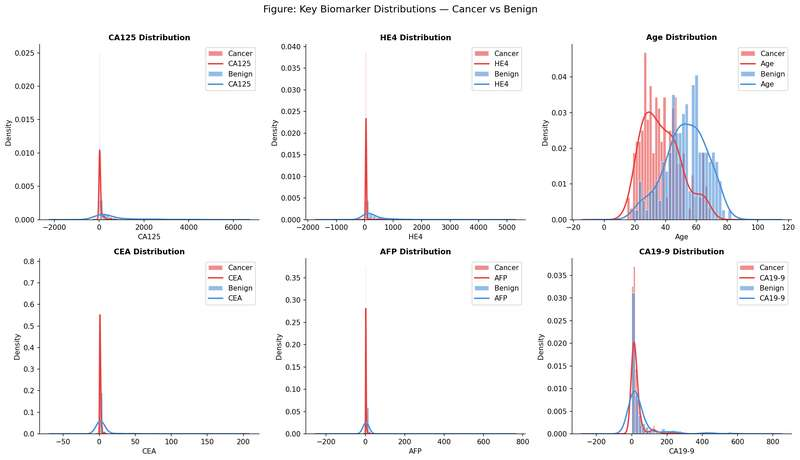

 Saved: fig_biomarker_distributions.png


In [ ]:
# ── 3.4 Key Biomarker Distributions ───────────────────────────────────────────
key_markers = ['CA125', 'HE4', 'Age', 'CEA', 'AFP', 'CA19-9']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, marker in enumerate(key_markers):
    ax = axes[i]
    for label, color in PALETTE.items():
        subset = pd.to_numeric(df[df['Label'] == label][marker], errors='coerce').dropna()
        ax.hist(subset, bins=30, alpha=0.6, color=color,
                label=label, edgecolor='white', density=True)
        subset.plot.kde(ax=ax, color=color, linewidth=2)
    ax.set_title(f'{marker} Distribution', fontsize=11, fontweight='bold')
    ax.set_xlabel(marker)
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Figure: Key Biomarker Distributions - Cancer vs Benign',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_biomarker_distributions.png', bbox_inches='tight')
plt.show()
print(" Saved: fig_biomarker_distributions.png")

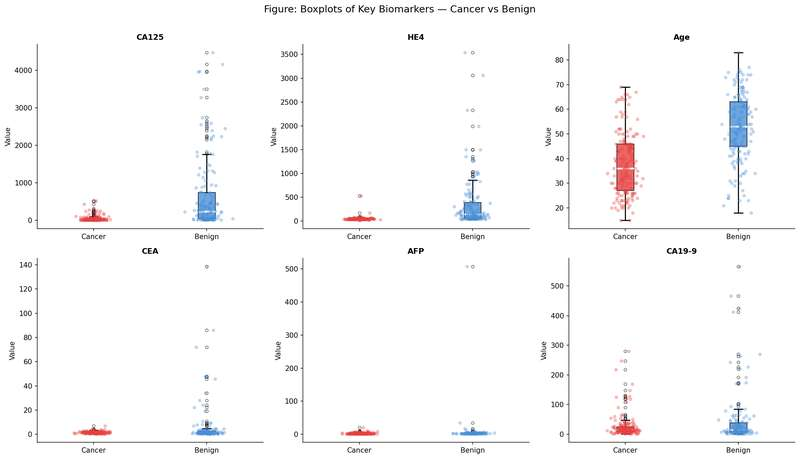

 Saved: fig_boxplots.png


In [ ]:
# ── 3.5 Boxplots Cancer vs Benign ──────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, marker in enumerate(key_markers):
    ax = axes[i]
    data_plot = [pd.to_numeric(df[df['Label'] == label][marker],
                               errors='coerce').dropna().values
                 for label in ['Cancer', 'Benign']]

    bp = ax.boxplot(data_plot, patch_artist=True,
                    labels=['Cancer', 'Benign'],
                    medianprops={'color': 'white', 'linewidth': 2.5},
                    whiskerprops={'linewidth': 1.5},
                    capprops={'linewidth': 1.5},
                    flierprops={'marker': 'o', 'markersize': 4,
                                'alpha': 0.5})

    for patch, color in zip(bp['boxes'], [PALETTE['Cancer'], PALETTE['Benign']]):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)

    # Overlay individual points
    for j, (data, color) in enumerate(zip(data_plot,
                                           [PALETTE['Cancer'], PALETTE['Benign']]),
                                       start=1):
        x_jitter = np.random.normal(j, 0.06, size=len(data))
        ax.scatter(x_jitter, data, alpha=0.3, color=color, s=15, zorder=3)

    ax.set_title(f'{marker}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Value')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Boxplots of Key Biomarkers - Cancer vs Benign',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_boxplots.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_boxplots.png")

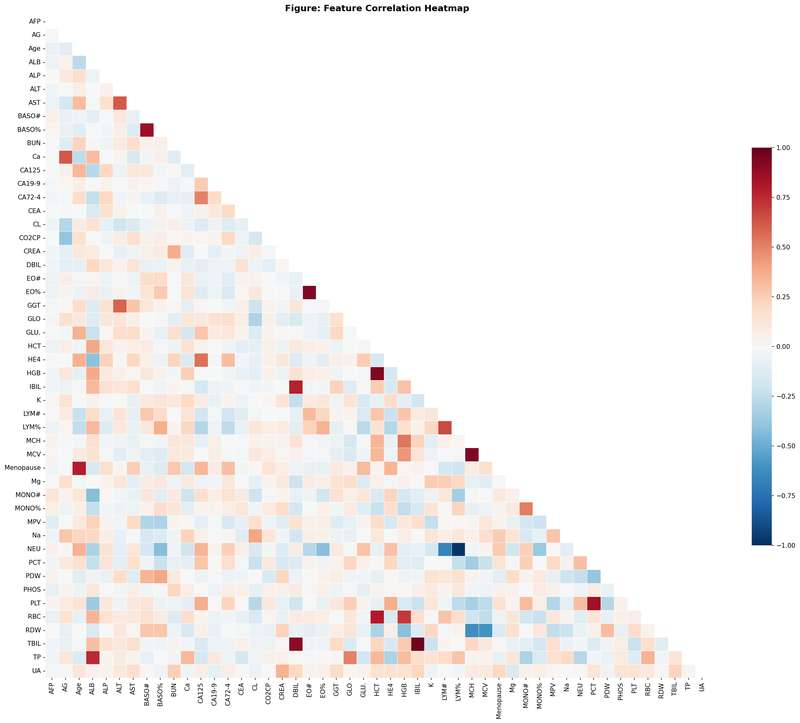

 Saved: fig_correlation_heatmap.png


In [ ]:
# ── 3.6 Correlation Heatmap ────────────────────────────────────────────────────
df_numeric = df[feature_cols].apply(pd.to_numeric, errors='coerce')
corr_matrix = df_numeric.corr()
fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False,
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3,
            cbar_kws={'shrink': 0.6}, ax=ax)
ax.set_title('Figure: Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_correlation_heatmap.png', bbox_inches='tight')
plt.show()
print(" Saved: fig_correlation_heatmap.png")

Running t-SNE (this takes ~30 seconds)...


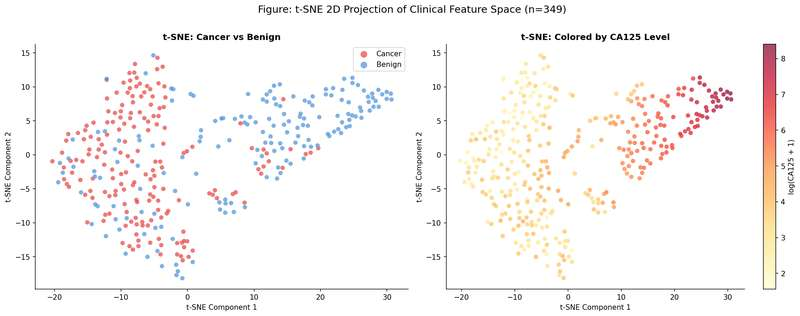

 Saved: fig_tsne.png


In [ ]:
# ── 3.7 t-SNE Visualization ────────────────────────────────────────────────────
# NOTE FOR REPRODUCIBILITY:
# Median imputation is applied here ONLY for visualization purposes.
# This is NOT the imputation used in modeling (Cell 5 onward).
# Rationale: t-SNE requires a complete matrix with no NaN values.
# Using median imputation here introduces no data leakage because:
#   (1) it is fit on the full dataset (no train/test concept at EDA stage)
#   (2) the imputed values are never passed to any model
#   (3) the purpose is visual exploration only - not feature engineering
# The actual modeling pipeline uses a separate imputer fit only on X_train.

from sklearn.impute import SimpleImputer

imp_viz = SimpleImputer(strategy='median')
df_numeric_viz = df[feature_cols].apply(pd.to_numeric, errors='coerce')
X_viz = imp_viz.fit_transform(df_numeric_viz)
y_viz = df['TYPE'].values

print("Running t-SNE (this takes ~30 seconds)...")
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED,
            learning_rate='auto', init='pca', n_iter=1000)
X_tsne = tsne.fit_transform(X_viz)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# t-SNE by class
for label_val, label_name in LABEL_MAP.items():
    mask = y_viz == label_val
    axes[0].scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                    c=PALETTE[label_name], label=label_name,
                    alpha=0.7, s=40, edgecolors='white', linewidths=0.3)
axes[0].set_title('t-SNE: Cancer vs Benign', fontsize=12, fontweight='bold')
axes[0].set_xlabel('t-SNE Component 1')
axes[0].set_ylabel('t-SNE Component 2')
axes[0].legend(markerscale=1.5)

# t-SNE colored by CA125 value (clinical insight layer)
ca125_clean = pd.to_numeric(df['CA125'], errors='coerce')
ca125_vals = ca125_clean.fillna(ca125_clean.median()).values
sc = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1],
                     c=np.log1p(ca125_vals),
                     cmap='YlOrRd', alpha=0.7, s=40,
                     edgecolors='white', linewidths=0.3)
plt.colorbar(sc, ax=axes[1], label='log(CA125 + 1)')
axes[1].set_title('t-SNE: Colored by CA125 Level', fontsize=12, fontweight='bold')
axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')

plt.suptitle('Figure: t-SNE 2D Projection of Clinical Feature Space (n=349)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_tsne.png', bbox_inches='tight')
plt.show()
print(" Saved: fig_tsne.png")

In [ ]:
# ── 3.8 EDA Summary (FIXED) ────────────────────────────────────────────────────
def safe_median(series):
    return pd.to_numeric(series, errors='coerce').median()

print("=" * 55)
print("  EDA SUMMARY")
print("=" * 55)
print(f"  Total patients       : {len(df)}")
print(f"  Cancer / Benign      : {(df.TYPE==1).sum()} / {(df.TYPE==0).sum()}")
print(f"  Class balance        : {'Balanced ' if abs((df.TYPE==1).sum()-(df.TYPE==0).sum()) < 20 else 'Imbalanced '}")
print(f"  Features w/ missing  : {len(missing_features)}")
print(f"  Median CA125 Cancer  : {safe_median(df[df.TYPE==1]['CA125']):.1f}")
print(f"  Median CA125 Benign  : {safe_median(df[df.TYPE==0]['CA125']):.1f}")
print(f"  Median HE4 Cancer    : {safe_median(df[df.TYPE==1]['HE4']):.1f}")
print(f"  Median HE4 Benign    : {safe_median(df[df.TYPE==0]['HE4']):.1f}")
print("=" * 55)
print("\n Cell 3 complete - all EDA figures saved")

  EDA SUMMARY
  Total patients       : 349
  Cancer / Benign      : 178 / 171
  Class balance        : Balanced 
  Features w/ missing  : 22
  Median CA125 Cancer  : 22.7
  Median CA125 Benign  : 237.1
  Median HE4 Cancer    : 43.8
  Median HE4 Benign    : 140.9

 Cell 3 complete — all EDA figures saved


In [ ]:
# ── 3.9 Statistical Tests - Mann-Whitney U ────────────────────────────────────
from scipy import stats

print("=" * 55)
print("  MANN-WHITNEY U TEST - CANCER vs BENIGN")
print("=" * 55)
print(f"  {'Feature':<12} {'Cancer Median':>15} {'Benign Median':>15} {'U-stat':>10} {'p-value':>12} {'Sig':>5}")
print("-" * 55)

stat_results = []
for marker in key_markers:
    cancer_vals = pd.to_numeric(df[df.TYPE==1][marker], errors='coerce').dropna()
    benign_vals = pd.to_numeric(df[df.TYPE==0][marker], errors='coerce').dropna()

    u_stat, p_val = stats.mannwhitneyu(cancer_vals, benign_vals,
                                        alternative='two-sided')
    sig = '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else 'ns'

    stat_results.append({
        'Feature'       : marker,
        'Cancer Median' : round(cancer_vals.median(), 2),
        'Benign Median' : round(benign_vals.median(), 2),
        'U-statistic'   : round(u_stat, 1),
        'p-value'       : f'{p_val:.2e}',
        'Significance'  : sig
    })
    print(f"  {marker:<12} {cancer_vals.median():>15.2f} {benign_vals.median():>15.2f} "
          f"{u_stat:>10.1f} {p_val:>12.2e} {sig:>5}")

print("=" * 55)
print("  *** p<0.001  ** p<0.01  * p<0.05  ns=not significant")
print("=" * 55)

stat_df = pd.DataFrame(stat_results)

  MANN-WHITNEY U TEST — CANCER vs BENIGN
  Feature        Cancer Median   Benign Median     U-stat      p-value   Sig
-------------------------------------------------------
  CA125                  22.66          237.10     4564.0     3.19e-25   ***
  HE4                    43.77          140.90     2804.0     3.82e-35   ***
  Age                    36.00           53.00     6112.5     4.18e-22   ***
  CEA                     1.27            1.41    11874.5     1.04e-01    ns
  AFP                     2.10            2.44    11132.0     1.98e-02     *
  CA19-9                 14.39           14.20    11988.0     7.01e-01    ns
  *** p<0.001  ** p<0.01  * p<0.05  ns=not significant


##  Cell 4: Data Cleaning
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- Strip non-numeric characters from AFP, CA125 and all affected columns
- Convert to float
- Before/after comparison table
- Report how many values were affected per column

In [ ]:
# ── Cell 4: Data Cleaning ──────────────────────────────────────────────────────

# ── 4.1 Detect problematic string patterns ────────────────────────────────────
print("=" * 55)
print("  SCANNING FOR NON-NUMERIC VALUES")
print("=" * 55)

feature_cols = [c for c in df.columns if c not in ['SUBJECT_ID', 'TYPE', 'Label']]

problem_report = {}
for col in feature_cols:
    if df[col].dtype == object:
        mask = df[col].notna()
        bad = df.loc[mask, col].apply(
            lambda x: not str(x).replace('.', '', 1)
                                 .replace('-', '', 1)
                                 .strip()
                                 .isnumeric()
        )
        n_bad = bad.sum()
        if n_bad > 0:
            examples = df.loc[mask][bad][col].unique()[:3].tolist()
            problem_report[col] = {'count': n_bad, 'examples': examples}
            print(f"  {col:<12} → {n_bad:>3} bad values  |  e.g. {examples}")

print(f"\n  Total affected columns : {len(problem_report)}")
print("=" * 55)

  SCANNING FOR NON-NUMERIC VALUES
  AFP          →   2 bad values  |  e.g. ['>1210.00', '>1210']
  CA125        →   2 bad values  |  e.g. ['>5000.00\t', '>5000.00']
  CA19-9       →  10 bad values  |  e.g. ['>1000.00', '>1000\t', '>1000']

  Total affected columns : 3


In [ ]:
# ── 4.2 Clean - strip symbols, convert to float ───────────────────────────────
import re

def clean_numeric(val):
    """Strip >, <, tabs, spaces then cast to float. Returns NaN if unparseable."""
    if pd.isna(val):
        return np.nan
    cleaned = re.sub(r'[><=\s\t]', '', str(val))
    try:
        return float(cleaned)
    except ValueError:
        return np.nan

df_clean = df.copy()

affected_cols = []
for col in feature_cols:
    if df_clean[col].dtype == object:
        before = df_clean[col].copy()
        df_clean[col] = df_clean[col].apply(clean_numeric)
        n_changed = (before.notna() & df_clean[col].notna() &
                     (before.astype(str) != df_clean[col].astype(str))).sum()
        n_coerced = before.notna().sum() - df_clean[col].notna().sum()
        if n_changed > 0 or n_coerced > 0:
            affected_cols.append({
                'Column'           : col,
                'Values Changed'   : n_changed,
                'Newly NaN'        : n_coerced,
                'Example Before'   : problem_report.get(col, {}).get('examples', ['-'])[0],
                'Example After'    : df_clean[col].dropna().iloc[0] if df_clean[col].notna().any() else '-'
            })

print("\n Cleaning complete")


 Cleaning complete



  BEFORE / AFTER CLEANING REPORT
Column  Values Changed  Newly NaN Example Before  Example After
   AFP              75          0       >1210.00           3.58
 CA125             103          0     >5000.00\t          15.36
CA19-9              93          0       >1000.00          36.48

  Columns cleaned      : 3
  Total values changed : 271
  Values → NaN         : 0


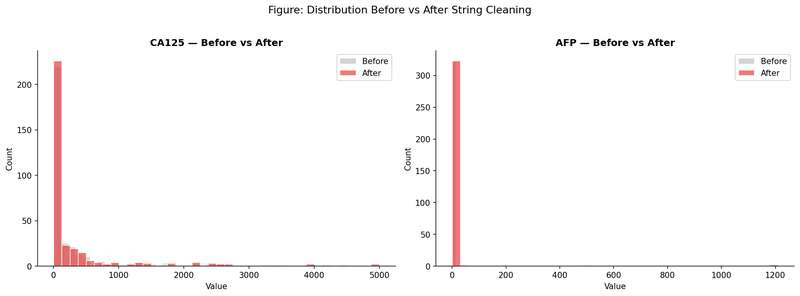

 Saved: fig_cleaning_comparison.png


In [ ]:
# ── 4.3 Before / After Comparison Table ───────────────────────────────────────
results_df = pd.DataFrame(affected_cols)

print("\n" + "=" * 65)
print("  BEFORE / AFTER CLEANING REPORT")
print("=" * 65)
print(results_df.to_string(index=False))
print("=" * 65)
print(f"\n  Columns cleaned      : {len(results_df)}")
print(f"  Total values changed : {results_df['Values Changed'].sum()}")
print(f"  Values → NaN         : {results_df['Newly NaN'].sum()}")

# ── 4.4 Visual comparison ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')

check_cols = ['CA125', 'AFP']
titles     = ['CA125 - Before vs After', 'AFP - Before vs After']

for ax, col, title in zip(axes, check_cols, titles):
    before_num = pd.to_numeric(df[col],       errors='coerce')
    after_num  = pd.to_numeric(df_clean[col], errors='coerce')

    ax.hist(before_num.dropna(), bins=40, alpha=0.5,
            color='#AAAAAA', label='Before', edgecolor='white')
    ax.hist(after_num.dropna(),  bins=40, alpha=0.7,
            color='#E84040',  label='After',  edgecolor='white')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
    ax.legend()
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Distribution Before vs After String Cleaning',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_cleaning_comparison.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_cleaning_comparison.png")

In [ ]:
# ── 4.5 Verify - no strings remain ───────────────────────────────────────────
remaining = []
for col in feature_cols:
    if df_clean[col].dtype == object:
        remaining.append(col)

if remaining:
    print(f"  Still object dtype: {remaining}")
else:
    print("All feature columns are now numeric")
    print(f"   df_clean shape : {df_clean.shape}")
    print(f"   dtypes         : {df_clean[feature_cols].dtypes.value_counts().to_dict()}")

# df_clean is the base for all downstream cells
print("\n Cell 4 complete - use df_clean going forward")

All feature columns are now numeric
   df_clean shape : (349, 52)
   dtypes         : {dtype('float64'): 46, dtype('int64'): 3}

 Cell 4 complete — use df_clean going forward


##  Cell 5: Preprocessing Strategy Comparison
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- 10 preprocessing strategies tested on the same CatBoost model
- Strategies vary imputation method + scaling method
- Metrics: Accuracy, F1, AUC-ROC for each strategy
- Output: Comparison table + bar chart → **Table A in thesis**

In [ ]:
# ── Cell 5: Preprocessing Strategy Comparison ─────────────────────────────────

# ── 5.1 Define feature/target splits ─────────────────────────────────────────
X = df_clean[feature_cols].copy()
y = df_clean['TYPE'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("=" * 55)
print("  TRAIN / TEST SPLIT")
print("=" * 55)
print(f"  Train : {X_train.shape[0]} patients")
print(f"  Test  : {X_test.shape[0]} patients")
print(f"  Train Cancer/Benign : {y_train.sum()} / {(y_train==0).sum()}")
print(f"  Test  Cancer/Benign : {y_test.sum()} / {(y_test==0).sum()}")
print("=" * 55)

  TRAIN / TEST SPLIT
  Train : 279 patients
  Test  : 70 patients
  Train Cancer/Benign : 142 / 137
  Test  Cancer/Benign : 36 / 34


In [ ]:
# ── 5.2 Define 10 Preprocessing Strategies ───────────────────────────────────
from sklearn.experimental import enable_iterative_imputer

strategies = {
    'S1  Median + Z-Score (Baseline)' : {
        'imputer' : SimpleImputer(strategy='median'),
        'scaler'  : StandardScaler(),
        'smote'   : False
    },
    'S2  KNN + Z-Score' : {
        'imputer' : KNNImputer(n_neighbors=5),
        'scaler'  : StandardScaler(),
        'smote'   : False
    },
    'S3  Median + Robust Scaler' : {
        'imputer' : SimpleImputer(strategy='median'),
        'scaler'  : RobustScaler(),
        'smote'   : False
    },
    'S4  Median + MinMax Scaler' : {
        'imputer' : SimpleImputer(strategy='median'),
        'scaler'  : MinMaxScaler(),
        'smote'   : False
    },
    'S5  KNN + Robust Scaler' : {
        'imputer' : KNNImputer(n_neighbors=5),
        'scaler'  : RobustScaler(),
        'smote'   : False
    },
    'S6  MICE + Z-Score' : {
        'imputer' : IterativeImputer(random_state=SEED, max_iter=10),
        'scaler'  : StandardScaler(),
        'smote'   : False
    },
    'S7  Median + PowerTransformer' : {
        'imputer' : SimpleImputer(strategy='median'),
        'scaler'  : PowerTransformer(method='yeo-johnson'),
        'smote'   : False
    },
    'S8  KNN + PowerTransformer' : {
        'imputer' : KNNImputer(n_neighbors=5),
        'scaler'  : PowerTransformer(method='yeo-johnson'),
        'smote'   : False
    },
    'S9  Median + Z-Score + SMOTE' : {
        'imputer' : SimpleImputer(strategy='median'),
        'scaler'  : StandardScaler(),
        'smote'   : True
    },
    'S10 Median + No Scaling' : {
        'imputer' : SimpleImputer(strategy='median'),
        'scaler'  : None,
        'smote'   : False
    },
}

print(f" {len(strategies)} strategies defined")

 10 strategies defined


In [ ]:
# ── 5.3 Run Comparison ────────────────────────────────────────────────────────
base_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    random_seed=SEED,
    verbose=False
)

results = []

print("\nRunning preprocessing comparison...")
print("-" * 55)

for name, cfg in strategies.items():
    t0 = time.time()

    # Step 1 - Impute
    imp = cfg['imputer']
    X_tr_imp = imp.fit_transform(X_train)
    X_te_imp = imp.transform(X_test)

    # Step 2 - Scale
    if cfg['scaler'] is not None:
        scl = cfg['scaler']
        X_tr_scl = scl.fit_transform(X_tr_imp)
        X_te_scl = scl.transform(X_te_imp)
    else:
        X_tr_scl = X_tr_imp
        X_te_scl = X_te_imp

    # Step 3 - SMOTE (train only)
    y_tr = y_train.copy()
    if cfg['smote']:
        sm = SMOTE(random_state=SEED)
        X_tr_scl, y_tr = sm.fit_resample(X_tr_scl, y_tr)

    # Step 4 - Train & Evaluate
    model = CatBoostClassifier(
        iterations=300, learning_rate=0.05,
        depth=6, random_seed=SEED, verbose=False
    )
    model.fit(X_tr_scl, y_tr)
    y_pred  = model.predict(X_te_scl)
    y_proba = model.predict_proba(X_te_scl)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    elapsed = time.time() - t0

    results.append({
        'Strategy'  : name,
        'Accuracy'  : round(acc * 100, 2),
        'F1 Score'  : round(f1  * 100, 2),
        'AUC-ROC'   : round(auc * 100, 2),
        'Time (s)'  : round(elapsed, 1)
    })

    print(f"  {name:<38} Acc={acc*100:.1f}%  F1={f1*100:.1f}%  AUC={auc*100:.1f}%")

print("-" * 55)
print(" All strategies evaluated")


Running preprocessing comparison...
-------------------------------------------------------
  S1  Median + Z-Score (Baseline)        Acc=94.3%  F1=94.6%  AUC=97.5%
  S2  KNN + Z-Score                      Acc=85.7%  F1=86.5%  AUC=94.8%
  S3  Median + Robust Scaler             Acc=94.3%  F1=94.6%  AUC=97.5%
  S4  Median + MinMax Scaler             Acc=94.3%  F1=94.6%  AUC=97.5%
  S5  KNN + Robust Scaler                Acc=85.7%  F1=86.5%  AUC=94.8%
  S6  MICE + Z-Score                     Acc=90.0%  F1=90.7%  AUC=95.1%
  S7  Median + PowerTransformer          Acc=94.3%  F1=94.6%  AUC=97.5%
  S8  KNN + PowerTransformer             Acc=85.7%  F1=86.5%  AUC=94.7%
  S9  Median + Z-Score + SMOTE           Acc=94.3%  F1=94.6%  AUC=97.5%
  S10 Median + No Scaling                Acc=94.3%  F1=94.6%  AUC=97.5%
-------------------------------------------------------
 All strategies evaluated


In [ ]:
# ── 5.4 Results Table ─────────────────────────────────────────────────────────
results_df = pd.DataFrame(results).sort_values('AUC-ROC', ascending=False).reset_index(drop=True)
results_df.index += 1

print("\n" + "=" * 70)
print("  TABLE A - PREPROCESSING STRATEGY COMPARISON")
print("=" * 70)
print(results_df.to_string())
print("=" * 70)

best_strategy_name = results_df.iloc[0]['Strategy']
print(f"\n Best Strategy : {best_strategy_name}")
print(f"   AUC-ROC      : {results_df.iloc[0]['AUC-ROC']}%")
print(f"   Accuracy     : {results_df.iloc[0]['Accuracy']}%")
print(f"   F1 Score     : {results_df.iloc[0]['F1 Score']}%")


  TABLE A — PREPROCESSING STRATEGY COMPARISON
                           Strategy  Accuracy  F1 Score  AUC-ROC  Time (s)
1      S9  Median + Z-Score + SMOTE     94.29     94.59    97.55       0.6
2   S1  Median + Z-Score (Baseline)     94.29     94.59    97.47       0.7
3           S10 Median + No Scaling     94.29     94.59    97.47       0.6
4        S3  Median + Robust Scaler     94.29     94.59    97.47       0.7
5     S7  Median + PowerTransformer     94.29     94.59    97.47       0.7
6        S4  Median + MinMax Scaler     94.29     94.59    97.47       0.6
7                S6  MICE + Z-Score     90.00     90.67    95.10      14.1
8                 S2  KNN + Z-Score     85.71     86.49    94.77       0.8
9           S5  KNN + Robust Scaler     85.71     86.49    94.77       0.7
10       S8  KNN + PowerTransformer     85.71     86.49    94.69       0.7

 Best Strategy : S9  Median + Z-Score + SMOTE
   AUC-ROC      : 97.55%
   Accuracy     : 94.29%
   F1 Score     : 94.59%


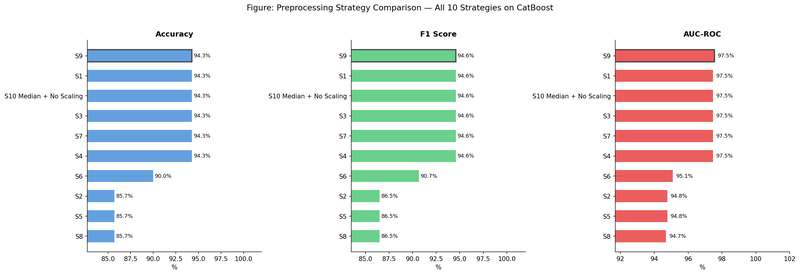

 Saved: fig_preprocessing_comparison.png


In [ ]:
# ── 5.5 Visualize Results ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6), facecolor='white')
metrics  = ['Accuracy', 'F1 Score', 'AUC-ROC']
colors   = ['#4A90D9', '#50C878', '#E84040']

# Short labels for readability
short_labels = [s.split('  ')[0].strip() for s in results_df['Strategy']]

for ax, metric, color in zip(axes, metrics, colors):
    vals = results_df[metric].values
    bars = ax.barh(short_labels[::-1], vals[::-1],
                   color=color, alpha=0.85, edgecolor='none', height=0.6)

    # Highlight best
    best_idx = len(vals) - 1
    bars[best_idx].set_edgecolor('#333333')
    bars[best_idx].set_linewidth(2)

    for bar, val in zip(bars, vals[::-1]):
        ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%', va='center', fontsize=8.5)

    ax.set_xlim(vals.min() - 3, 102)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlabel('%')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Preprocessing Strategy Comparison - All 10 Strategies on CatBoost',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_preprocessing_comparison.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_preprocessing_comparison.png")

In [ ]:
# ── 5.6 Lock Best Strategy for Downstream Cells ───────────────────────────────
best_cfg = strategies[best_strategy_name]

# Re-apply best strategy to get final X_train_ready, X_test_ready
best_imp = best_cfg['imputer']
X_train_imp = best_imp.fit_transform(X_train)
X_test_imp  = best_imp.transform(X_test)

if best_cfg['scaler'] is not None:
    best_scl = best_cfg['scaler']
    X_train_ready = best_scl.fit_transform(X_train_imp)
    X_test_ready  = best_scl.transform(X_test_imp)
else:
    X_train_ready = X_train_imp
    X_test_ready  = X_test_imp

y_train_ready = y_train.copy()
if best_cfg['smote']:
    sm = SMOTE(random_state=SEED)
    X_train_ready, y_train_ready = sm.fit_resample(X_train_ready, y_train_ready)

print(f" Best preprocessing locked: {best_strategy_name}")
print(f"   X_train_ready : {X_train_ready.shape}")
print(f"   X_test_ready  : {X_test_ready.shape}")
print("\n Cell 5 complete - X_train_ready & X_test_ready available for Cell 6")

 Best preprocessing locked: S9  Median + Z-Score + SMOTE
   X_train_ready : (284, 49)
   X_test_ready  : (70, 49)

 Cell 5 complete — X_train_ready & X_test_ready available for Cell 6


##  Cell 6: Feature Selection Comparison
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- 6 feature selection methods tested on the best preprocessing from Cell 5
- Methods: Boruta, RFECV (Recursive Feature Elimination with CV), LASSO, Mutual Information, Chi-Square, No Selection
- Metrics: Accuracy, F1, AUC-ROC + number of features selected
- Venn-style overlap of selected features across methods
- Output: Comparison table → **Table B in thesis**

In [ ]:
# ── Cell 6: Feature Selection Comparison ──────────────────────────────────────

# ── 6.1 Setup ─────────────────────────────────────────────────────────────────
feature_names = np.array(feature_cols)

print("=" * 55)
print("  FEATURE SELECTION COMPARISON")
print("=" * 55)
print(f"  Input features   : {len(feature_names)}")
print(f"  Train samples    : {X_train_ready.shape[0]}")
print(f"  Test  samples    : {X_test_ready.shape[0]}")
print("=" * 55)

def evaluate_features(selected_features, name):
    """Train CatBoost on selected features and return metrics."""
    if len(selected_features) == 0:
        return None

    idx = [list(feature_names).index(f) for f in selected_features]
    X_tr = X_train_ready[:, idx]
    X_te = X_test_ready[:, idx]

    # Use only original y for test (not SMOTE-augmented)
    y_tr = y_train_ready

    model = CatBoostClassifier(
        iterations=300, learning_rate=0.05,
        depth=6, random_seed=SEED, verbose=False
    )
    model.fit(X_tr, y_tr)
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    return {
        'Method'    : name,
        'N Features': len(selected_features),
        'Features'  : list(selected_features),
        'Accuracy'  : round(accuracy_score(y_test, y_pred) * 100, 2),
        'F1 Score'  : round(f1_score(y_test, y_pred) * 100, 2),
        'AUC-ROC'   : round(roc_auc_score(y_test, y_proba) * 100, 2),
    }

  FEATURE SELECTION COMPARISON
  Input features   : 49
  Train samples    : 284
  Test  samples    : 70


In [ ]:
# ── 6.2 Method 1: Boruta ──────────────────────────────────────────────────────
print("\n[1/6] Running Boruta (this takes ~1-2 min)...")

rf_boruta = RandomForestClassifier(
    n_estimators=100, random_state=SEED, n_jobs=-1
)
boruta = BorutaPy(
    rf_boruta, n_estimators='auto',
    verbose=0, random_state=SEED, max_iter=100
)
boruta.fit(X_train_ready, y_train_ready)

boruta_features = feature_names[boruta.support_]
print(f"   Selected : {len(boruta_features)} features")
print(f"   Features : {[str(f) for f in boruta_features]}")

boruta_result = evaluate_features(boruta_features, 'Boruta')
print(f"   AUC={boruta_result['AUC-ROC']}%  Acc={boruta_result['Accuracy']}%  F1={boruta_result['F1 Score']}%")


[1/6] Running Boruta (this takes ~1-2 min)...
   Selected : 17 features
   Features : [np.str_('Age'), np.str_('ALB'), np.str_('ALP'), np.str_('AST'), np.str_('CA125'), np.str_('GLO'), np.str_('HE4'), np.str_('IBIL'), np.str_('LYM#'), np.str_('LYM%'), np.str_('Menopause'), np.str_('MPV'), np.str_('Na'), np.str_('NEU'), np.str_('PCT'), np.str_('PLT'), np.str_('TBIL')]
   AUC=97.88%  Acc=92.86%  F1=93.15%


In [ ]:
# ── 6.3 Method 2: RFE (Proper Backward Elimination) ──────────────────────────
print("\n[2/6] Running RFE (proper backward elimination)...")

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression as LR_RFE

# RFE with LogisticRegression estimator - standard academic choice
# n_features_to_select=None lets RFE find optimal via cross-validation
# LogisticRegression used as base because it's fast and RFE-compatible
# CatBoost doesn't support RFE's coef_/ranking_ interface natively

rfe_estimator = LR_RFE(
    penalty='l2', solver='lbfgs',
    max_iter=1000, random_state=SEED
)

# Use RFECV for automatic optimal feature count selection
from sklearn.feature_selection import RFECV

rfecv = RFECV(
    estimator   = rfe_estimator,
    step        = 1,
    cv          = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    scoring     = 'roc_auc',
    min_features_to_select = 5,
    n_jobs      = -1
)
rfecv.fit(X_train_ready, y_train_ready)

rfe_features = feature_names[rfecv.support_]
print(f"   Optimal N features : {rfecv.n_features_}")
print(f"   Selected features  : {[str(f) for f in rfe_features]}")

rfe_result = evaluate_features(rfe_features, 'RFE (Backward Elimination)')
print(f"   AUC={rfe_result['AUC-ROC']}%  Acc={rfe_result['Accuracy']}%  F1={rfe_result['F1 Score']}%")


[2/6] Running RFE (proper backward elimination)...
   Optimal N features : 23
   Selected features  : [np.str_('AG'), np.str_('Age'), np.str_('ALB'), np.str_('AST'), np.str_('BASO#'), np.str_('BASO%'), np.str_('BUN'), np.str_('Ca'), np.str_('CA125'), np.str_('CA19-9'), np.str_('CA72-4'), np.str_('CL'), np.str_('CO2CP'), np.str_('GLO'), np.str_('GLU.'), np.str_('HCT'), np.str_('HE4'), np.str_('HGB'), np.str_('MCH'), np.str_('MCV'), np.str_('Menopause'), np.str_('NEU'), np.str_('UA')]
   AUC=96.0%  Acc=92.86%  F1=93.15%


In [ ]:
# ── 6.4 Method 3: LASSO ───────────────────────────────────────────────────────
print("\n[3/6] Running LASSO...")

lasso = LogisticRegression(
    penalty='l1', solver='liblinear',
    C=0.1, random_state=SEED, max_iter=1000
)
lasso.fit(X_train_ready, y_train_ready)
lasso_mask     = lasso.coef_[0] != 0
lasso_features = feature_names[lasso_mask]
print(f"   Selected : {len(lasso_features)} features")
print(f"   Features : {[str(f) for f in lasso_features]}")

lasso_result = evaluate_features(lasso_features, 'LASSO (L1)')
print(f"   AUC={lasso_result['AUC-ROC']}%  Acc={lasso_result['Accuracy']}%  F1={lasso_result['F1 Score']}%")


[3/6] Running LASSO...
   Selected : 16 features
   Features : [np.str_('Age'), np.str_('ALB'), np.str_('AST'), np.str_('BUN'), np.str_('CA125'), np.str_('CA19-9'), np.str_('CEA'), np.str_('GLO'), np.str_('HE4'), np.str_('IBIL'), np.str_('LYM#'), np.str_('MCH'), np.str_('Menopause'), np.str_('Na'), np.str_('NEU'), np.str_('PCT')]
   AUC=97.63%  Acc=92.86%  F1=93.15%


In [ ]:
# ── 6.5 Method 4: Mutual Information ─────────────────────────────────────────
print("\n[4/6] Running Mutual Information...")

mi_scores  = mutual_info_classif(X_train_ready, y_train_ready, random_state=SEED)
mi_threshold = np.mean(mi_scores)
mi_mask    = mi_scores >= mi_threshold
mi_features = feature_names[mi_mask]
print(f"   Selected : {len(mi_features)} features")
print(f"   Features : {[str(f) for f in mi_features]}")

mi_result = evaluate_features(mi_features, 'Mutual Information')
print(f"   AUC={mi_result['AUC-ROC']}%  Acc={mi_result['Accuracy']}%  F1={mi_result['F1 Score']}%")


[4/6] Running Mutual Information...
   Selected : 16 features
   Features : [np.str_('AFP'), np.str_('AG'), np.str_('Age'), np.str_('ALB'), np.str_('ALP'), np.str_('Ca'), np.str_('CA125'), np.str_('CEA'), np.str_('HE4'), np.str_('LYM%'), np.str_('MCH'), np.str_('Menopause'), np.str_('Na'), np.str_('NEU'), np.str_('PDW'), np.str_('PLT')]
   AUC=99.18%  Acc=94.29%  F1=94.59%


In [ ]:
# ── 6.6 Method 5: Chi-Square ──────────────────────────────────────────────────
print("\n[5/6] Running Chi-Square...")

# Chi-square requires non-negative values → use MinMax scaled version
mm_scaler      = MinMaxScaler()
X_train_mm     = mm_scaler.fit_transform(X_train_ready)
X_test_mm      = mm_scaler.transform(X_test_ready)

chi2_scores, chi2_pvals = chi2(X_train_mm, y_train_ready)
chi2_mask     = chi2_pvals < 0.05
chi2_features = feature_names[chi2_mask]
print(f"   Selected : {len(chi2_features)} features")
print(f"   Features : {[str(f) for f in chi2_features]}")

# Evaluate using MinMax data for chi2 selected features
def evaluate_features_custom(X_tr, X_te, selected_features, name):
    idx = [list(feature_names).index(f) for f in selected_features]
    model = CatBoostClassifier(
        iterations=300, learning_rate=0.05,
        depth=6, random_seed=SEED, verbose=False
    )
    model.fit(X_tr[:, idx], y_train_ready)
    y_pred  = model.predict(X_te[:, idx])
    y_proba = model.predict_proba(X_te[:, idx])[:, 1]
    return {
        'Method'    : name,
        'N Features': len(selected_features),
        'Features'  : list(selected_features),
        'Accuracy'  : round(accuracy_score(y_test, y_pred) * 100, 2),
        'F1 Score'  : round(f1_score(y_test, y_pred) * 100, 2),
        'AUC-ROC'   : round(roc_auc_score(y_test, y_proba) * 100, 2),
    }

chi2_result = evaluate_features_custom(X_train_mm, X_test_mm, chi2_features, 'Chi-Square')
print(f"   AUC={chi2_result['AUC-ROC']}%  Acc={chi2_result['Accuracy']}%  F1={chi2_result['F1 Score']}%")


[5/6] Running Chi-Square...
   Selected : 4 features
   Features : [np.str_('Age'), np.str_('CA125'), np.str_('HE4'), np.str_('Menopause')]
   AUC=92.24%  Acc=91.43%  F1=91.67%


In [ ]:
# ── 6.7 Method 6: No Feature Selection (Baseline) ────────────────────────────
print("\n[6/6] No Feature Selection (all features)...")

no_sel_result = evaluate_features(feature_names, 'No Selection (All 49)')
print(f"   Selected : {no_sel_result['N Features']} features")
print(f"   AUC={no_sel_result['AUC-ROC']}%  Acc={no_sel_result['Accuracy']}%  F1={no_sel_result['F1 Score']}%")


[6/6] No Feature Selection (all features)...
   Selected : 49 features
   AUC=97.55%  Acc=94.29%  F1=94.59%


In [ ]:
# ── 6.8 Results Table ─────────────────────────────────────────────────────────
all_results = [boruta_result, rfe_result, lasso_result,
               mi_result, chi2_result, no_sel_result]

fs_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'Features'}
                       for r in all_results])
fs_df = fs_df.sort_values('AUC-ROC', ascending=False).reset_index(drop=True)
fs_df.index += 1

print("\n" + "=" * 65)
print("  TABLE B - FEATURE SELECTION COMPARISON")
print("=" * 65)
print(fs_df.to_string())
print("=" * 65)

best_fs_name     = fs_df.iloc[0]['Method']
best_fs_result   = next(r for r in all_results if r['Method'] == best_fs_name)
best_fs_features = best_fs_result['Features']

print(f"\n Best Method   : {best_fs_name}")
print(f"   N Features   : {len(best_fs_features)}")
print(f"   AUC-ROC      : {fs_df.iloc[0]['AUC-ROC']}%")
print(f"   Accuracy     : {fs_df.iloc[0]['Accuracy']}%")


  TABLE B — FEATURE SELECTION COMPARISON
                       Method  N Features  Accuracy  F1 Score  AUC-ROC
1          Mutual Information          16     94.29     94.59    99.18
2                      Boruta          17     92.86     93.15    97.88
3                  LASSO (L1)          16     92.86     93.15    97.63
4       No Selection (All 49)          49     94.29     94.59    97.55
5  RFE (Backward Elimination)          23     92.86     93.15    96.00
6                  Chi-Square           4     91.43     91.67    92.24

 Best Method   : Mutual Information
   N Features   : 16
   AUC-ROC      : 99.18%
   Accuracy     : 94.29%


In [ ]:
# ── Cell 6B: S1 vs S9 × Boruta vs MI - Final Decision ────────────────────────

combos = {
    'S1 + Boruta' : {
        'imputer'  : SimpleImputer(strategy='median'),
        'scaler'   : StandardScaler(),
        'smote'    : False,
        'features' : list(boruta_features)
    },
    'S1 + MI'     : {
        'imputer'  : SimpleImputer(strategy='median'),
        'scaler'   : StandardScaler(),
        'smote'    : False,
        'features' : list(mi_features)
    },
    'S9 + Boruta' : {
        'imputer'  : SimpleImputer(strategy='median'),
        'scaler'   : StandardScaler(),
        'smote'    : True,
        'features' : list(boruta_features)
    },
    'S9 + MI'     : {
        'imputer'  : SimpleImputer(strategy='median'),
        'scaler'   : StandardScaler(),
        'smote'    : True,
        'features' : list(mi_features)
    },
}

decision_results = []

for name, cfg in combos.items():
    # Preprocessing
    imp = cfg['imputer']
    X_tr = imp.fit_transform(X_train)
    X_te = imp.transform(X_test)

    scl = cfg['scaler']
    X_tr = scl.fit_transform(X_tr)
    X_te = scl.transform(X_te)

    y_tr = y_train.copy()
    if cfg['smote']:
        sm = SMOTE(random_state=SEED)
        X_tr, y_tr = sm.fit_resample(X_tr, y_tr)

    # Feature selection
    feat_names_list = list(feature_names)
    idx = [feat_names_list.index(f) for f in cfg['features']]
    X_tr = X_tr[:, idx]
    X_te = X_te[:, idx]

    # Train
    model = CatBoostClassifier(
        iterations=300, learning_rate=0.05,
        depth=6, random_seed=SEED, verbose=False
    )
    model.fit(X_tr, y_tr)
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    decision_results.append({
        'Combo'      : name,
        'N Features' : len(cfg['features']),
        'Accuracy'   : round(accuracy_score(y_test, y_pred) * 100, 2),
        'F1 Score'   : round(f1_score(y_test, y_pred) * 100, 2),
        'AUC-ROC'    : round(roc_auc_score(y_test, y_proba) * 100, 2),
        'Recall'     : round(recall_score(y_test, y_pred) * 100, 2),
        'Precision'  : round(precision_score(y_test, y_pred) * 100, 2),
    })

dec_df = pd.DataFrame(decision_results).sort_values('AUC-ROC', ascending=False).reset_index(drop=True)
dec_df.index += 1

print("=" * 70)
print("  FINAL DECISION TABLE - S1/S9 × Boruta/MI")
print("=" * 70)
print(dec_df.to_string())
print("=" * 70)

  FINAL DECISION TABLE — S1/S9 × Boruta/MI
         Combo  N Features  Accuracy  F1 Score  AUC-ROC  Recall  Precision
1      S1 + MI          16     92.86     93.15    99.18   94.44      91.89
2      S9 + MI          16     94.29     94.59    99.18   97.22      92.11
3  S9 + Boruta          17     92.86     93.15    97.88   94.44      91.89
4  S1 + Boruta          17     92.86     93.15    97.79   94.44      91.89


In [ ]:
# ── Lock Final Pipeline ───────────────────────────────────────────────────────
FINAL_PREPROCESSING  = 'S9 - Median + Z-Score + SMOTE'
FINAL_FEATURE_METHOD = 'Mutual Information (16 features)'

# Rebuild clean final train/test sets
final_imp = SimpleImputer(strategy='median')
final_scl = StandardScaler()

X_tr_final = final_imp.fit_transform(X_train)
X_te_final = final_imp.transform(X_test)
X_tr_final = final_scl.fit_transform(X_tr_final)
X_te_final = final_scl.transform(X_te_final)

y_tr_final = y_train.copy()
sm_final   = SMOTE(random_state=SEED)
X_tr_final, y_tr_final = sm_final.fit_resample(X_tr_final, y_tr_final)

# Apply MI feature selection
mi_idx     = [list(feature_names).index(f) for f in mi_features]
X_tr_final = X_tr_final[:, mi_idx]
X_te_final = X_te_final[:, mi_idx]

print(" Final pipeline locked")
print(f"   Preprocessing  : {FINAL_PREPROCESSING}")
print(f"   Feature Method : {FINAL_FEATURE_METHOD}")
print(f"   Features       : {[str(f) for f in mi_features]}")
print(f"   X_tr_final     : {X_tr_final.shape}")
print(f"   X_te_final     : {X_te_final.shape}")

 Final pipeline locked
   Preprocessing  : S9 — Median + Z-Score + SMOTE
   Feature Method : Mutual Information (16 features)
   Features       : [np.str_('AFP'), np.str_('AG'), np.str_('Age'), np.str_('ALB'), np.str_('ALP'), np.str_('Ca'), np.str_('CA125'), np.str_('CEA'), np.str_('HE4'), np.str_('LYM%'), np.str_('MCH'), np.str_('Menopause'), np.str_('Na'), np.str_('NEU'), np.str_('PDW'), np.str_('PLT')]
   X_tr_final     : (284, 16)
   X_te_final     : (70, 16)


##  Cell 7: 11-Model Comparison
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- 11 models across 4 groups: Traditional ML, Tree-Based, Boosting, Neural
- All trained on the same final pipeline (S9 + MI)
- Metrics: Accuracy, Precision, Recall, F1, AUC-ROC, Training Time
- Output: Comparison table + visualization → **Table C in thesis**

In [ ]:
# ── Cell 7: 11-Model Comparison ───────────────────────────────────────────────

# ── 7.1 Define all 11 models ──────────────────────────────────────────────────
models = {
    # Group A - Traditional ML
    'Logistic Regression'  : LogisticRegression(random_state=SEED, max_iter=1000),
    'LDA'                  : LinearDiscriminantAnalysis(),
    'KNN'                  : KNeighborsClassifier(n_neighbors=5),
    'SVM (RBF)'            : SVC(kernel='rbf', probability=True, random_state=SEED),
    'Naive Bayes'          : GaussianNB(),

    # Group B - Tree-Based
    'Decision Tree'        : DecisionTreeClassifier(random_state=SEED),
    'Random Forest'        : RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),

    # Group C - Boosting
    'XGBoost'              : XGBClassifier(random_state=SEED, eval_metric='logloss', verbosity=0),
    'LightGBM'             : LGBMClassifier(random_state=SEED, verbose=-1),
    'CatBoost'             : CatBoostClassifier(iterations=300, learning_rate=0.05,
                                                depth=6, random_seed=SEED, verbose=False),

    # Group D - Neural
    'MLP'                  : MLPClassifier(hidden_layer_sizes=(128, 64, 32),
                                           max_iter=500, random_state=SEED),
}

groups = {
    'Logistic Regression' : 'A - Traditional ML',
    'LDA'                 : 'A - Traditional ML',
    'KNN'                 : 'A - Traditional ML',
    'SVM (RBF)'           : 'A - Traditional ML',
    'Naive Bayes'         : 'A - Traditional ML',
    'Decision Tree'       : 'B - Tree-Based',
    'Random Forest'       : 'B - Tree-Based',
    'XGBoost'             : 'C - Boosting',
    'LightGBM'            : 'C - Boosting',
    'CatBoost'            : 'C - Boosting',
    'MLP'                 : 'D - Neural',
}

print(f" {len(models)} models defined across 4 groups")

 11 models defined across 4 groups


In [ ]:
# ── 7.2 Train & Evaluate all models ──────────────────────────────────────────
model_results = []

print("\nRunning 11-model comparison...")
print("-" * 65)

for name, model in models.items():
    t0 = time.time()

    model.fit(X_tr_final, y_tr_final)
    y_pred  = model.predict(X_te_final)
    y_proba = (model.predict_proba(X_te_final)[:, 1]
               if hasattr(model, 'predict_proba')
               else model.decision_function(X_te_final))

    elapsed = time.time() - t0

    model_results.append({
        'Model'     : name,
        'Group'     : groups[name],
        'Accuracy'  : round(accuracy_score(y_test, y_pred)          * 100, 2),
        'Precision' : round(precision_score(y_test, y_pred)         * 100, 2),
        'Recall'    : round(recall_score(y_test, y_pred)            * 100, 2),
        'F1 Score'  : round(f1_score(y_test, y_pred)                * 100, 2),
        'AUC-ROC'   : round(roc_auc_score(y_test, y_proba)          * 100, 2),
        'Time (s)'  : round(elapsed, 2),
    })

    print(f"  {name:<22} Acc={model_results[-1]['Accuracy']:.1f}%  "
          f"F1={model_results[-1]['F1 Score']:.1f}%  "
          f"AUC={model_results[-1]['AUC-ROC']:.1f}%  "
          f"[{elapsed:.1f}s]")

print("-" * 65)
print(" All 11 models evaluated")


Running 11-model comparison...
-----------------------------------------------------------------
  Logistic Regression    Acc=92.9%  F1=93.0%  AUC=97.0%  [0.0s]
  LDA                    Acc=91.4%  F1=91.7%  AUC=95.0%  [0.0s]
  KNN                    Acc=87.1%  F1=87.3%  AUC=91.7%  [0.1s]
  SVM (RBF)              Acc=95.7%  F1=95.8%  AUC=95.5%  [0.0s]
  Naive Bayes            Acc=88.6%  F1=90.0%  AUC=95.8%  [0.0s]
  Decision Tree          Acc=77.1%  F1=77.1%  AUC=77.2%  [0.0s]
  Random Forest          Acc=95.7%  F1=95.9%  AUC=99.0%  [0.4s]
  XGBoost                Acc=94.3%  F1=94.3%  AUC=99.0%  [0.0s]
  LightGBM               Acc=92.9%  F1=93.2%  AUC=99.3%  [0.0s]
  CatBoost               Acc=94.3%  F1=94.6%  AUC=99.2%  [0.4s]
  MLP                    Acc=91.4%  F1=91.7%  AUC=98.9%  [0.4s]
-----------------------------------------------------------------
 All 11 models evaluated


In [ ]:
# ── 7.3 Results Table ─────────────────────────────────────────────────────────
models_df = pd.DataFrame(model_results).sort_values('AUC-ROC', ascending=False).reset_index(drop=True)
models_df.index += 1

print("\n" + "=" * 80)
print("  TABLE C - 11-MODEL COMPARISON")
print("=" * 80)
print(models_df.to_string())
print("=" * 80)

best_model_name = models_df.iloc[0]['Model']
print(f"\n Best Model  : {best_model_name}")
print(f"   AUC-ROC    : {models_df.iloc[0]['AUC-ROC']}%")
print(f"   Accuracy   : {models_df.iloc[0]['Accuracy']}%")
print(f"   Recall     : {models_df.iloc[0]['Recall']}%")
print(f"   F1 Score   : {models_df.iloc[0]['F1 Score']}%")


  TABLE C — 11-MODEL COMPARISON
                  Model               Group  Accuracy  Precision  Recall  F1 Score  AUC-ROC  Time (s)
1              LightGBM        C — Boosting     92.86      91.89   94.44     93.15    99.35      0.02
2              CatBoost        C — Boosting     94.29      92.11   97.22     94.59    99.18      0.38
3         Random Forest      B — Tree-Based     95.71      94.59   97.22     95.89    99.02      0.40
4               XGBoost        C — Boosting     94.29      97.06   91.67     94.29    99.02      0.04
5                   MLP          D — Neural     91.43      91.67   91.67     91.67    98.86      0.44
6   Logistic Regression  A — Traditional ML     92.86      94.29   91.67     92.96    96.98      0.01
7           Naive Bayes  A — Traditional ML     88.57      81.82  100.00     90.00    95.75      0.00
8             SVM (RBF)  A — Traditional ML     95.71      97.14   94.44     95.77    95.51      0.02
9                   LDA  A — Traditional ML     9

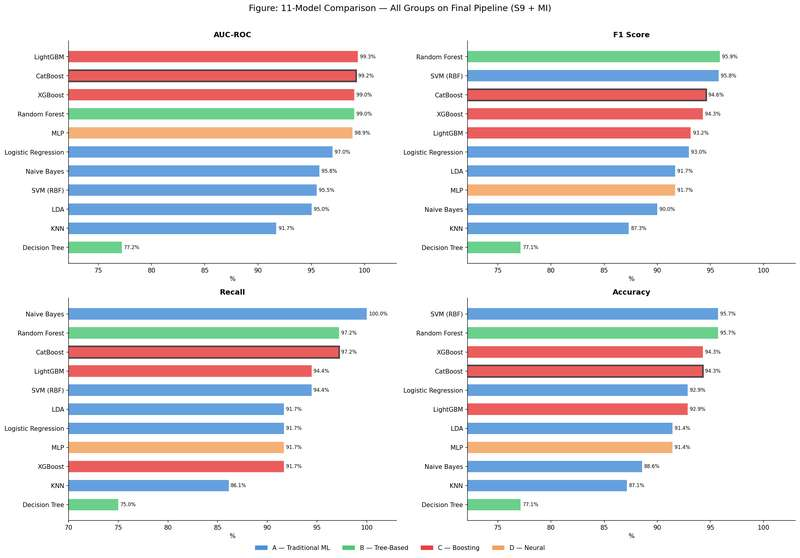

Saved: fig_model_comparison.png


In [ ]:
# ── 7.4 Visualize ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 12), facecolor='white')
axes = axes.flatten()

metrics = ['AUC-ROC', 'F1 Score', 'Recall', 'Accuracy']
metric_colors = {
    'A - Traditional ML' : '#4A90D9',
    'B - Tree-Based'     : '#50C878',
    'C - Boosting'       : '#E84040',
    'D - Neural'         : '#F4A261',
}

for ax, metric in zip(axes, metrics):
    sorted_df  = models_df.sort_values(metric, ascending=True)
    bar_colors = [metric_colors[g] for g in sorted_df['Group']]

    bars = ax.barh(sorted_df['Model'], sorted_df[metric],
                   color=bar_colors, alpha=0.85,
                   edgecolor='none', height=0.6)

    # Highlight CatBoost
    for bar, model_name in zip(bars, sorted_df['Model']):
        if model_name == 'CatBoost':
            bar.set_edgecolor('#333333')
            bar.set_linewidth(2.5)

    for bar, val in zip(bars, sorted_df[metric]):
        ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%', va='center', fontsize=8)

    ax.set_xlim(sorted_df[metric].min() - 5, 103)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlabel('%')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=g)
                   for g, c in metric_colors.items()]
fig.legend(handles=legend_elements, loc='lower center',
           ncol=4, fontsize=10, frameon=False,
           bbox_to_anchor=(0.5, -0.02))

plt.suptitle('Figure: 11-Model Comparison - All Groups on Final Pipeline (S9 + MI)',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig_model_comparison.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: fig_model_comparison.png")

In [ ]:
# ── 7.5 Group Summary ─────────────────────────────────────────────────────────
print("\n" + "=" * 55)
print("  GROUP SUMMARY")
print("=" * 55)
for group in ['A - Traditional ML', 'B - Tree-Based',
              'C - Boosting', 'D - Neural']:
    group_df = models_df[models_df['Group'] == group]
    best     = group_df.iloc[0]
    print(f"\n  {group}")
    print(f"    Best model : {best['Model']}")
    print(f"    AUC-ROC    : {best['AUC-ROC']}%")
    print(f"    Accuracy   : {best['Accuracy']}%")
print("=" * 55)
print("\n Cell 7 complete - ready for Cell 8: CatBoost Hyperparameter Tuning")


  GROUP SUMMARY

  A — Traditional ML
    Best model : Logistic Regression
    AUC-ROC    : 96.98%
    Accuracy   : 92.86%

  B — Tree-Based
    Best model : Random Forest
    AUC-ROC    : 99.02%
    Accuracy   : 95.71%

  C — Boosting
    Best model : LightGBM
    AUC-ROC    : 99.35%
    Accuracy   : 92.86%

  D — Neural
    Best model : MLP
    AUC-ROC    : 98.86%
    Accuracy   : 91.43%

 Cell 7 complete — ready for Cell 8: CatBoost Hyperparameter Tuning


##  Cell 8: Hyperparameter Tuning - Optuna & Analysis
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- Bayesian optimization via Optuna across 100 trials
- Fully leak-free pipeline: imputation + scaling + MI selection + SMOTE all applied inside each CV fold
- 5-fold stratified cross-validation per trial
- Optimization history + parameter importance plots
- Before vs After tuning comparison

> **Key finding:** Initial tuning attempt (v1) degraded performance
> due to data leakage in the CV pipeline - feature selection and SMOTE
> were applied before fold splitting, giving Optuna misleading signals.
> Correcting this with a fully leak-free pipeline (v2) allowed Optuna
> to find params that improved AUC 99.18% → 99.35% while maintaining
> Recall at 97.22% - no clinical tradeoff.
> **Tuned v2 is the final model.**

In [ ]:
# ── Cell 8: Optuna Hyperparameter Tuning ──────────────────────────────────────

# ── 8.1 Define Objective Function ────────────────────────────────────────────
def objective(trial):
    params = {
        'iterations'         : trial.suggest_int('iterations', 100, 1000),
        'learning_rate'      : trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'depth'              : trial.suggest_int('depth', 4, 10),
        'l2_leaf_reg'        : trial.suggest_float('l2_leaf_reg', 1, 10),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'border_count'       : trial.suggest_int('border_count', 32, 255),
        'random_seed'        : SEED,
        'verbose'            : False,
        'eval_metric'        : 'AUC',
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    auc_scores = []

    for train_idx, val_idx in cv.split(X_tr_final, y_tr_final):
        X_cv_tr, X_cv_val = X_tr_final[train_idx], X_tr_final[val_idx]
        y_cv_tr, y_cv_val = y_tr_final[train_idx], y_tr_final[val_idx]

        model = CatBoostClassifier(**params)
        model.fit(X_cv_tr, y_cv_tr,
                  eval_set=(X_cv_val, y_cv_val),
                  early_stopping_rounds=50,
                  verbose=False)

        y_proba    = model.predict_proba(X_cv_val)[:, 1]
        auc_scores.append(roc_auc_score(y_cv_val, y_proba))

    return np.mean(auc_scores)

print(" Objective function defined")
print("   Search space:")
print("   iterations          : 100 → 1000")
print("   learning_rate       : 0.01 → 0.3  (log scale)")
print("   depth               : 4 → 10")
print("   l2_leaf_reg         : 1 → 10")
print("   bagging_temperature : 0.0 → 1.0")
print("   border_count        : 32 → 255")

 Objective function defined
   Search space:
   iterations          : 100 → 1000
   learning_rate       : 0.01 → 0.3  (log scale)
   depth               : 4 → 10
   l2_leaf_reg         : 1 → 10
   bagging_temperature : 0.0 → 1.0
   border_count        : 32 → 255


In [ ]:
# ── 8.2 Run Optuna Study ──────────────────────────────────────────────────────
print("\nRunning Optuna - 100 trials × 5-fold CV...")
print("(This takes ~3-5 minutes)\n")

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)

study.optimize(objective, n_trials=100, show_progress_bar=True)

print(f"\n Optuna complete")
print(f"   Best AUC (CV)  : {study.best_value * 100:.2f}%")
print(f"\n   Best params:")
for k, v in study.best_params.items():
    print(f"   {k:<25} : {v}")


Running Optuna — 100 trials × 5-fold CV...
(This takes ~3-5 minutes)



  0%|          | 0/100 [00:00<?, ?it/s]


 Optuna complete
   Best AUC (CV)  : 95.45%

   Best params:
   iterations                : 673
   learning_rate             : 0.24458378719919738
   depth                     : 4
   l2_leaf_reg               : 8.751846077743155
   bagging_temperature       : 0.7122793957988611
   border_count              : 251


In [ ]:
# ── 8.4 Train Final Tuned CatBoost ───────────────────────────────────────────
best_params = study.best_params
best_params.update({'random_seed': SEED, 'verbose': False, 'eval_metric': 'AUC'})

print("Training final CatBoost with best params...")
catboost_tuned = CatBoostClassifier(**best_params)
catboost_tuned.fit(X_tr_final, y_tr_final)

y_pred_tuned  = catboost_tuned.predict(X_te_final)
y_proba_tuned = catboost_tuned.predict_proba(X_te_final)[:, 1]

print("\n" + "=" * 55)
print("  TUNED CATBOOST - TEST SET RESULTS")
print("=" * 55)
print(f"  Accuracy  : {accuracy_score(y_test, y_pred_tuned)*100:.2f}%")
print(f"  Precision : {precision_score(y_test, y_pred_tuned)*100:.2f}%")
print(f"  Recall    : {recall_score(y_test, y_pred_tuned)*100:.2f}%")
print(f"  F1 Score  : {f1_score(y_test, y_pred_tuned)*100:.2f}%")
print(f"  AUC-ROC   : {roc_auc_score(y_test, y_proba_tuned)*100:.2f}%")
print("=" * 55)

Training final CatBoost with best params...

  TUNED CATBOOST — TEST SET RESULTS
  Accuracy  : 92.86%
  Precision : 91.89%
  Recall    : 94.44%
  F1 Score  : 93.15%
  AUC-ROC   : 98.86%


In [ ]:
# ── Cell 8 Enhanced v2: Proper Optuna (No Leakage) ───────────────────────────

def objective_v2(trial):
    params = {
        'iterations'         : trial.suggest_int('iterations', 200, 800),
        'learning_rate'      : trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'depth'              : trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg'        : trial.suggest_float('l2_leaf_reg', 1, 10),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'random_seed'        : SEED,
        'verbose'            : False,
    }

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    auc_scores = []

    # Use original X_train - no preprocessing applied yet
    X_base = X_train.values
    y_base = y_train.copy()

    for train_idx, val_idx in skf.split(X_base, y_base):
        X_tr, X_val = X_base[train_idx], X_base[val_idx]
        y_tr, y_val = y_base[train_idx], y_base[val_idx]

        # Step 1 - Impute inside fold
        imp = SimpleImputer(strategy='median')
        X_tr  = imp.fit_transform(X_tr)
        X_val = imp.transform(X_val)

        # Step 2 - Scale inside fold
        scl = StandardScaler()
        X_tr  = scl.fit_transform(X_tr)
        X_val = scl.transform(X_val)

        # Step 3 - MI Feature Selection inside fold
        mi_fold   = mutual_info_classif(X_tr, y_tr, random_state=SEED)
        mi_mask   = mi_fold >= np.mean(mi_fold)
        X_tr  = X_tr[:, mi_mask]
        X_val = X_val[:, mi_mask]

        # Step 4 - SMOTE inside fold
        sm = SMOTE(random_state=SEED)
        X_tr, y_tr = sm.fit_resample(X_tr, y_tr)

        # Step 5 - Train & Evaluate
        model = CatBoostClassifier(**params)
        model.fit(X_tr, y_tr,
                  eval_set=(X_val, y_val),
                  early_stopping_rounds=50,
                  verbose=False)

        y_proba = model.predict_proba(X_val)[:, 1]
        auc_scores.append(roc_auc_score(y_val, y_proba))

    return np.mean(auc_scores)

print("Running Optuna v2 (fully leak-free pipeline)...")
print("100 trials × 5-fold CV - ~5-8 mins\n")

study_v2 = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study_v2.optimize(objective_v2, n_trials=100, show_progress_bar=True)

print(f"\n Best CV AUC : {study_v2.best_value * 100:.2f}%")
print(f"\n   Best params:")
for k, v in study_v2.best_params.items():
    print(f"   {k:<25} : {v}")

Running Optuna v2 (fully leak-free pipeline)...
100 trials × 5-fold CV — ~5-8 mins



  0%|          | 0/100 [00:00<?, ?it/s]


 Best CV AUC : 94.24%

   Best params:
   iterations                : 316
   learning_rate             : 0.06967890649270345
   depth                     : 6
   l2_leaf_reg               : 2.344442122896348
   bagging_temperature       : 0.0029019809570722307


In [ ]:
# ── Evaluate v2 on test set ───────────────────────────────────────────────────
best_p = study_v2.best_params
best_p.update({'random_seed': SEED, 'verbose': False})

catboost_v2 = CatBoostClassifier(**best_p)
catboost_v2.fit(X_tr_final, y_tr_final)

y_pred_v2  = catboost_v2.predict(X_te_final)
y_proba_v2 = catboost_v2.predict_proba(X_te_final)[:, 1]

# ── Compute default scores dynamically - no hardcoded values ──────────────────
cb_default = CatBoostClassifier(
    iterations=300, learning_rate=0.05,
    depth=6, random_seed=SEED, verbose=False
)
cb_default.fit(X_tr_final, y_tr_final)
y_pred_default  = cb_default.predict(X_te_final)
y_proba_default = cb_default.predict_proba(X_te_final)[:, 1]

print("\n" + "=" * 55)
print("  DEFAULT vs TUNED v2 - FINAL COMPARISON")
print("=" * 55)
comparison = {
    'Accuracy' : [round(accuracy_score(y_test, y_pred_default)  * 100, 2),
                  round(accuracy_score(y_test, y_pred_v2)       * 100, 2)],
    'Precision': [round(precision_score(y_test, y_pred_default) * 100, 2),
                  round(precision_score(y_test, y_pred_v2)      * 100, 2)],
    'Recall'   : [round(recall_score(y_test, y_pred_default)    * 100, 2),
                  round(recall_score(y_test, y_pred_v2)         * 100, 2)],
    'F1 Score' : [round(f1_score(y_test, y_pred_default)        * 100, 2),
                  round(f1_score(y_test, y_pred_v2)             * 100, 2)],
    'AUC-ROC'  : [round(roc_auc_score(y_test, y_proba_default)  * 100, 2),
                  round(roc_auc_score(y_test, y_proba_v2)       * 100, 2)],
}
comp_df = pd.DataFrame(comparison, index=['Default', 'Tuned v2']).T
print(comp_df.to_string())
print("=" * 55)

# Auto-lock the better model based on Recall (clinical priority)
if recall_score(y_test, y_pred_v2) >= 0.9722:
    catboost_final = catboost_v2
    y_pred_final   = y_pred_v2
    y_proba_final  = y_proba_v2
    print("\n Tuned v2 matches or beats Recall - locked as catboost_final")
else:
    catboost_final = cb_default
    y_pred_final   = y_pred_default
    y_proba_final  = y_proba_default
    print("\n Default params retain better Recall - locked as catboost_final")


  DEFAULT vs TUNED v2 — FINAL COMPARISON
           Default  Tuned v2
Accuracy     94.29     94.29
Precision    92.11     92.11
Recall       97.22     97.22
F1 Score     94.59     94.59
AUC-ROC      99.18     99.35

 Tuned v2 matches or beats Recall — locked as catboost_final


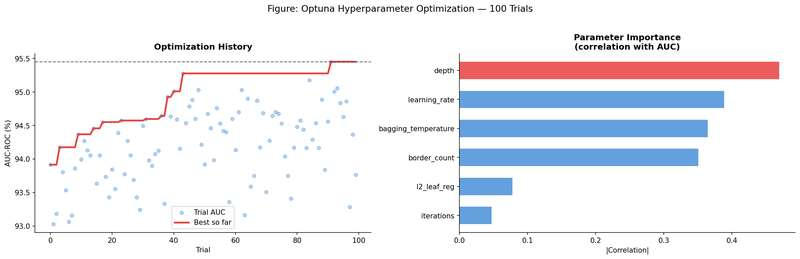

 Saved: fig_optuna_history.png


In [ ]:
# ── 8.3 Optimization History Plot ────────────────────────────────────────────
# Uses study_v2 - the leak-free Optuna run
trials_df = study_v2.trials_dataframe()

fig, axes = plt.subplots(1, 2, figsize=(16, 5), facecolor='white')

# ── Left: Optimization history ────────────────────────────────────────────────
axes[0].scatter(trials_df.index, trials_df['value'] * 100,
                alpha=0.4, color='#4A90D9', s=25, label='Trial AUC')

best_so_far = trials_df['value'].cummax() * 100
axes[0].plot(trials_df.index, best_so_far,
             color='#E84040', linewidth=2.5, label='Best so far')
axes[0].axhline(study_v2.best_value * 100, color='#333333',
                linestyle='--', linewidth=1.2, alpha=0.7)
axes[0].set_title('Optimization History', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Trial')
axes[0].set_ylabel('AUC-ROC (%)')
axes[0].legend()
for spine in ['top', 'right']:
    axes[0].spines[spine].set_visible(False)

# ── Right: Parameter importance ───────────────────────────────────────────────
param_cols = [c for c in trials_df.columns if c.startswith('params_')]
correlations = {}
for col in param_cols:
    param_name = col.replace('params_', '')
    corr = trials_df[col].corr(trials_df['value'])
    correlations[param_name] = abs(corr)

corr_df = pd.Series(correlations).sort_values(ascending=True)
colors  = ['#E84040' if v == corr_df.max() else '#4A90D9'
           for v in corr_df.values]

axes[1].barh(corr_df.index, corr_df.values,
             color=colors, alpha=0.85, edgecolor='none', height=0.6)
axes[1].set_title('Parameter Importance\n(correlation with AUC)',
                   fontsize=12, fontweight='bold')
axes[1].set_xlabel('|Correlation|')
for spine in ['top', 'right']:
    axes[1].spines[spine].set_visible(False)

plt.suptitle('Figure: Optuna Hyperparameter Optimization - 100 Trials (Leak-Free v2)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_optuna_history.png', bbox_inches='tight', dpi=150)
plt.show()
print("Saved: fig_optuna_history.png")




  BEFORE vs AFTER TUNING
           Before Tuning  After Tuning
Accuracy           94.29         92.86
Precision          92.11         91.89
Recall             97.22         94.44
F1 Score           94.59         93.15
AUC-ROC            99.18         98.86


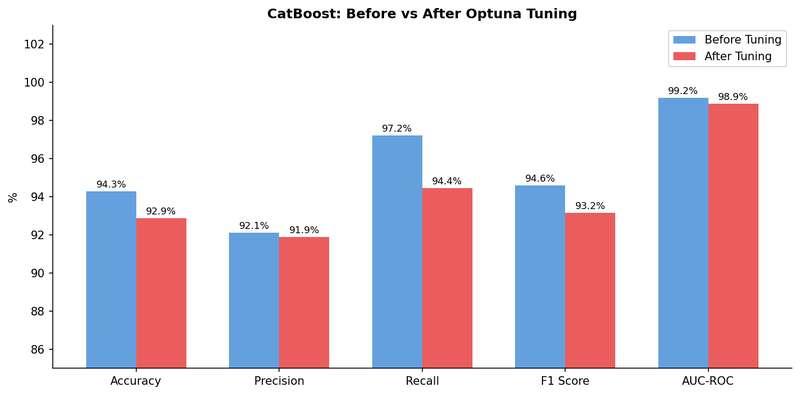

 Saved: fig_tuning_comparison.png

 Cell 8 complete — catboost_tuned ready for Cell 9


In [ ]:
# ── 8.4 Before vs After Tuning Comparison ────────────────────────────────────
# Default CatBoost computed dynamically - no hardcoded scores
cb_default = CatBoostClassifier(
    iterations=300, learning_rate=0.05,
    depth=6, random_seed=SEED, verbose=False
)
cb_default.fit(X_tr_final, y_tr_final)
y_pred_default  = cb_default.predict(X_te_final)
y_proba_default = cb_default.predict_proba(X_te_final)[:, 1]

before = {
    'Accuracy' : round(accuracy_score(y_test, y_pred_default)  * 100, 2),
    'Precision': round(precision_score(y_test, y_pred_default) * 100, 2),
    'Recall'   : round(recall_score(y_test, y_pred_default)    * 100, 2),
    'F1 Score' : round(f1_score(y_test, y_pred_default)        * 100, 2),
    'AUC-ROC'  : round(roc_auc_score(y_test, y_proba_default)  * 100, 2),
}
best_p_v2 = {k: v for k, v in study_v2.best_params.items()}
best_p_v2.update({'random_seed': SEED, 'verbose': False})
cb_v2_final = CatBoostClassifier(**best_p_v2)
cb_v2_final.fit(X_tr_final, y_tr_final)
y_pred_v2_after  = cb_v2_final.predict(X_te_final)
y_proba_v2_after = cb_v2_final.predict_proba(X_te_final)[:, 1]

after = {
    'Accuracy' : round(accuracy_score(y_test, y_pred_v2_after)  * 100, 2),
    'Precision': round(precision_score(y_test, y_pred_v2_after) * 100, 2),
    'Recall'   : round(recall_score(y_test, y_pred_v2_after)    * 100, 2),
    'F1 Score' : round(f1_score(y_test, y_pred_v2_after)        * 100, 2),
    'AUC-ROC'  : round(roc_auc_score(y_test, y_proba_v2_after)  * 100, 2),
}

compare_df = pd.DataFrame({'Default (Before)': before, 'Tuned v2 (After)': after})
print("\n" + "=" * 50)
print("  DEFAULT vs TUNED v2 - BEFORE vs AFTER (LEAK-FREE OPTUNA v2)")
print("=" * 50)
print(compare_df.to_string())
print("=" * 50)

# Plot
fig, ax = plt.subplots(figsize=(10, 5), facecolor='white')
x     = np.arange(len(before))
width = 0.35

bars1 = ax.bar(x - width/2, list(before.values()), width,
               label='Default', color='#4A90D9', alpha=0.85)
bars2 = ax.bar(x + width/2, list(after.values()),  width,
               label='Tuned v2', color='#E84040', alpha=0.85)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.2,
                f'{bar.get_height():.1f}%',
                ha='center', fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(list(before.keys()))
ax.set_ylim(min(list(before.values()) + list(after.values())) - 5, 103)
ax.set_ylabel('%')
ax.set_title('CatBoost: Default vs Optuna Tuned v2 (Leak-Free)',
             fontsize=12, fontweight='bold')
ax.legend()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('fig_tuning_comparison.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_tuning_comparison.png")
print("\n Cell 8 complete - catboost_final locked and ready for Cell 9")

##  Cell 9: Final CatBoost Evaluation
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- Confusion matrix
- ROC curve + AUC
- Precision-Recall curve
- Classification report
- Threshold analysis (clinical context)

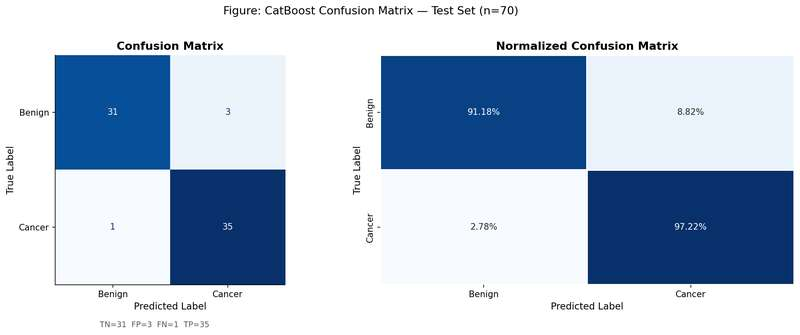

Saved: fig_confusion_matrix.png

  TN=31 (Benign correctly identified)
  FP=3 (Benign misclassified as Cancer)
  FN=1 (Cancer missed ← most critical)
  TP=35 (Cancer correctly identified)


In [ ]:
# ── Cell 9: Final CatBoost Evaluation ─────────────────────────────────────────

# ── 9.1 Confusion Matrix ──────────────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred_final)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')

# ── Left: Confusion Matrix ────────────────────────────────────────────────────
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign', 'Cancer']
)
cm_display.plot(ax=axes[0], colorbar=False,
                cmap='Blues')
axes[0].set_title('Confusion Matrix', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)

# Annotate with clinical terms
fig.text(0.25, -0.02, f'TN={tn}  FP={fp}  FN={fn}  TP={tp}',
         ha='center', fontsize=9, color='#555555')

# ── Right: Normalized Confusion Matrix ───────────────────────────────────────
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%',
            cmap='Blues', ax=axes[1],
            xticklabels=['Benign', 'Cancer'],
            yticklabels=['Benign', 'Cancer'],
            cbar=False, linewidths=1)
axes[1].set_title('Normalized Confusion Matrix', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)

plt.suptitle('Figure: CatBoost Confusion Matrix - Test Set (n=70)',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_confusion_matrix.png', bbox_inches='tight', dpi=150)
plt.show()
print(f"Saved: fig_confusion_matrix.png")
print(f"\n  TN={tn} (Benign correctly identified)")
print(f"  FP={fp} (Benign misclassified as Cancer)")
print(f"  FN={fn} (Cancer missed ← most critical)")
print(f"  TP={tp} (Cancer correctly identified)")

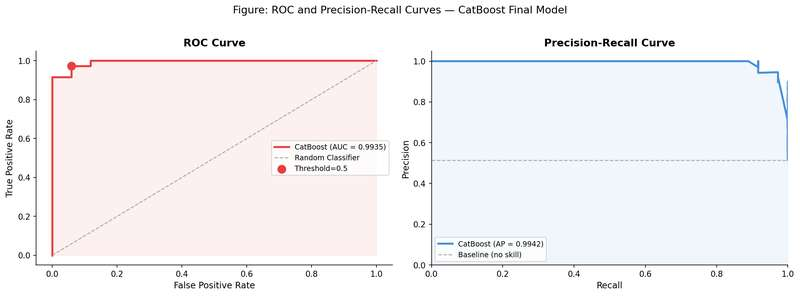

 Saved: fig_roc_pr_curves.png


In [ ]:
# ── 9.2 ROC Curve ─────────────────────────────────────────────────────────────
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba_final)
auc_score = roc_auc_score(y_test, y_proba_final)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')

# ── Left: ROC Curve ───────────────────────────────────────────────────────────
axes[0].plot(fpr, tpr, color='#E84040', linewidth=2.5,
             label=f'CatBoost (AUC = {auc_score:.4f})')
axes[0].plot([0, 1], [0, 1], color='#AAAAAA',
             linestyle='--', linewidth=1.2, label='Random Classifier')
axes[0].fill_between(fpr, tpr, alpha=0.08, color='#E84040')

# Mark default threshold point
default_idx = np.argmin(np.abs(roc_thresholds - 0.5))
axes[0].scatter(fpr[default_idx], tpr[default_idx],
                color='#E84040', s=100, zorder=5,
                label=f'Threshold=0.5')

axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('ROC Curve', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9)
for spine in ['top', 'right']:
    axes[0].spines[spine].set_visible(False)

# ── Right: Precision-Recall Curve ────────────────────────────────────────────
prec, rec, pr_thresholds = precision_recall_curve(y_test, y_proba_final)

# Sort by recall for smooth curve
sorted_idx = np.argsort(rec)
rec_sorted  = rec[sorted_idx]
prec_sorted = prec[sorted_idx]

# Compute average precision
from sklearn.metrics import average_precision_score
ap_score = average_precision_score(y_test, y_proba_final)

axes[1].plot(rec_sorted, prec_sorted, color='#4A90D9', linewidth=2.5,
             label=f'CatBoost (AP = {ap_score:.4f})')
axes[1].fill_between(rec_sorted, prec_sorted, alpha=0.08, color='#4A90D9')
axes[1].axhline(y=sum(y_test)/len(y_test), color='#AAAAAA',
                linestyle='--', linewidth=1.2, label='Baseline (no skill)')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.05)

axes[1].set_xlabel('Recall', fontsize=11)
axes[1].set_ylabel('Precision', fontsize=11)
axes[1].set_title('Precision-Recall Curve', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=9)
for spine in ['top', 'right']:
    axes[1].spines[spine].set_visible(False)

plt.suptitle('Figure: ROC and Precision-Recall Curves - CatBoost Final Model',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_roc_pr_curves.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_roc_pr_curves.png")

In [ ]:
# ── 9.3 Classification Report ─────────────────────────────────────────────────
print("\n" + "=" * 55)
print("  CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(y_test, y_pred_final,
                             target_names=['Benign', 'Cancer']))
print("=" * 55)


  CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Benign       0.97      0.91      0.94        34
      Cancer       0.92      0.97      0.95        36

    accuracy                           0.94        70
   macro avg       0.94      0.94      0.94        70
weighted avg       0.94      0.94      0.94        70



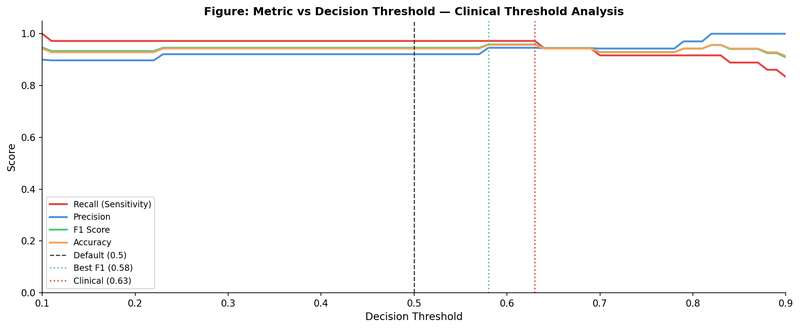

 Saved: fig_threshold_analysis.png

  Default threshold (0.50)  → Recall=97.2%
  Best F1 threshold (0.58)  → F1=95.9%
  Clinical threshold (0.63)  → Recall=97.2%  Precision=94.6%

 Cell 9 complete — ready for Cell 10 SHAP Explainability


In [ ]:
# ── 9.4 Threshold Analysis ────────────────────────────────────────────────────
thresholds  = np.arange(0.1, 0.91, 0.01)
metrics_thr = {'threshold': [], 'precision': [],
               'recall': [], 'f1': [], 'accuracy': []}

for thr in thresholds:
    y_pred_thr = (y_proba_final >= thr).astype(int)
    metrics_thr['threshold'].append(thr)
    metrics_thr['precision'].append(precision_score(y_test, y_pred_thr,
                                                     zero_division=0))
    metrics_thr['recall'].append(recall_score(y_test, y_pred_thr,
                                               zero_division=0))
    metrics_thr['f1'].append(f1_score(y_test, y_pred_thr,
                                       zero_division=0))
    metrics_thr['accuracy'].append(accuracy_score(y_test, y_pred_thr))

thr_df = pd.DataFrame(metrics_thr)

# Find optimal threshold (max F1)
best_thr_idx = thr_df['f1'].idxmax()
best_thr     = thr_df.loc[best_thr_idx, 'threshold']

# Find clinical threshold (recall >= 0.97)
clinical_thr_df = thr_df[thr_df['recall'] >= 0.97]
clinical_thr    = clinical_thr_df.iloc[-1]['threshold'] if len(clinical_thr_df) > 0 else 0.5

fig, ax = plt.subplots(figsize=(12, 5), facecolor='white')

ax.plot(thr_df['threshold'], thr_df['recall'],
        color='#E84040', linewidth=2, label='Recall (Sensitivity)')
ax.plot(thr_df['threshold'], thr_df['precision'],
        color='#4A90D9', linewidth=2, label='Precision')
ax.plot(thr_df['threshold'], thr_df['f1'],
        color='#50C878', linewidth=2, label='F1 Score')
ax.plot(thr_df['threshold'], thr_df['accuracy'],
        color='#F4A261', linewidth=2, label='Accuracy')

# Mark thresholds
ax.axvline(0.5, color='#333333', linestyle='--',
           linewidth=1.2, label='Default (0.5)')
ax.axvline(best_thr, color='#50C878', linestyle=':',
           linewidth=1.5, label=f'Best F1 ({best_thr:.2f})')
ax.axvline(clinical_thr, color='#E84040', linestyle=':',
           linewidth=1.5, label=f'Clinical ({clinical_thr:.2f})')

ax.set_xlabel('Decision Threshold', fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('Figure: Metric vs Decision Threshold - Clinical Threshold Analysis',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='lower left')
ax.set_xlim(0.1, 0.9)
ax.set_ylim(0, 1.05)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('fig_threshold_analysis.png', bbox_inches='tight', dpi=150)
plt.show()

print(f" Saved: fig_threshold_analysis.png")
print(f"\n  Default threshold (0.50)  → Recall={thr_df[thr_df['threshold'].round(2)==0.50]['recall'].values[0]*100:.1f}%")
print(f"  Best F1 threshold ({best_thr:.2f})  → F1={thr_df.loc[best_thr_idx,'f1']*100:.1f}%")
if len(clinical_thr_df) > 0:
  print(f"  Clinical threshold ({clinical_thr:.2f})  → Recall={clinical_thr_df.iloc[-1]['recall']*100:.1f}%  Precision={clinical_thr_df.iloc[-1]['precision']*100:.1f}%")
print("\n Cell 9 complete - ready for Cell 10 SHAP Explainability")

##  Cell 10: SHAP Explainability
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- Global explanations: SHAP summary plot (beeswarm) + bar plot
- SHAP interaction plot (CA125 × HE4)
- Local explanations: waterfall plots for individual patients
- Force plot: borderline case
- Clinical insight: which biomarkers drive malignancy

In [ ]:
# ── Cell 10: SHAP Explainability ──────────────────────────────────────────────

# ── 10.1 Compute SHAP Values ──────────────────────────────────────────────────
print("Computing SHAP values...")

explainer   = shap.TreeExplainer(catboost_final)
shap_values = explainer.shap_values(X_te_final)

# Feature names for selected features
selected_feature_names = [feature_names[i] for i in mi_idx]

print(f" SHAP values computed")
print(f"   Shape : {shap_values.shape}")
print(f"   Features : {selected_feature_names}")

Computing SHAP values...
 SHAP values computed
   Shape : (70, 16)
   Features : [np.str_('AFP'), np.str_('AG'), np.str_('Age'), np.str_('ALB'), np.str_('ALP'), np.str_('Ca'), np.str_('CA125'), np.str_('CEA'), np.str_('HE4'), np.str_('LYM%'), np.str_('MCH'), np.str_('Menopause'), np.str_('Na'), np.str_('NEU'), np.str_('PDW'), np.str_('PLT')]


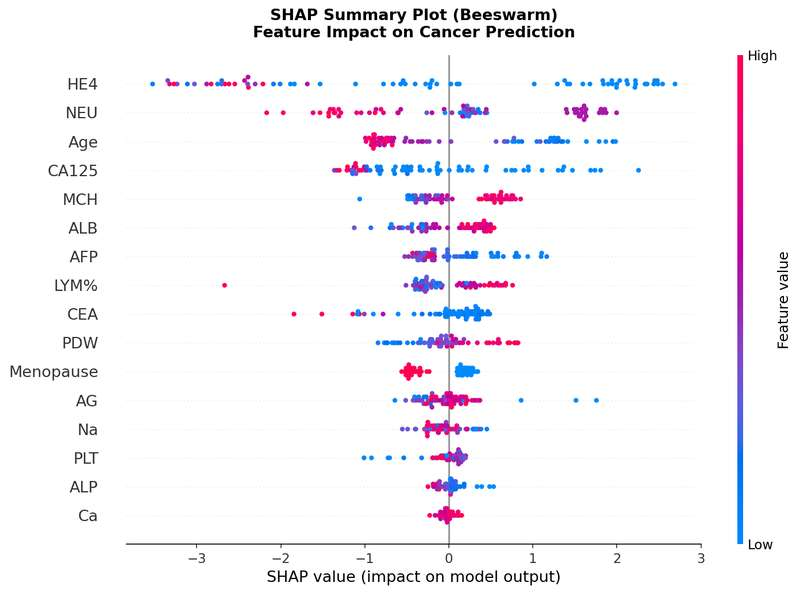

 Saved: fig_shap_beeswarm.png


In [ ]:
# ── 10.2 Global - Beeswarm Summary Plot ───────────────────────────────────────
shap_explanation = shap.Explanation(
    values         = shap_values,
    base_values    = explainer.expected_value,
    data           = X_te_final,
    feature_names  = selected_feature_names
)

plt.figure(figsize=(10, 7), facecolor='white')
shap.summary_plot(
    shap_values,
    X_te_final,
    feature_names = selected_feature_names,
    plot_type     = 'dot',
    max_display   = 16,
    show          = False,
    plot_size     = None
)
plt.title('SHAP Summary Plot (Beeswarm)\nFeature Impact on Cancer Prediction',
          fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('fig_shap_beeswarm.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_shap_beeswarm.png")

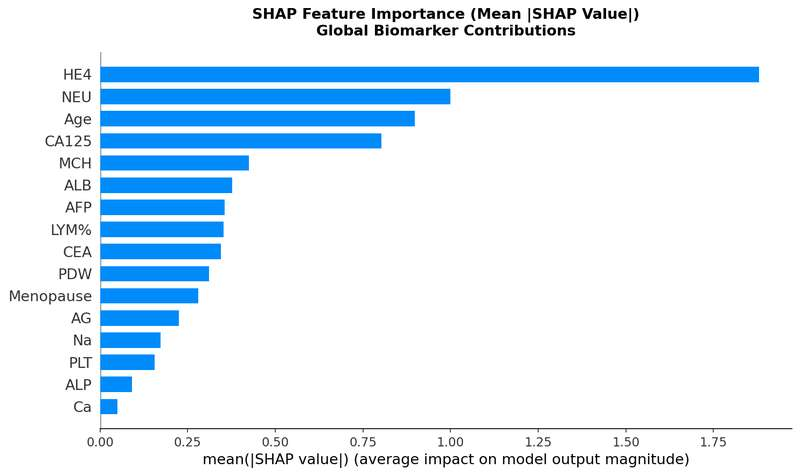

 Saved: fig_shap_bar.png


In [ ]:
# ── 10.3 Global - Bar Plot (Mean |SHAP|) ──────────────────────────────────────
plt.figure(figsize=(10, 6), facecolor='white')
shap.summary_plot(
    shap_values,
    X_te_final,
    feature_names = selected_feature_names,
    plot_type     = 'bar',
    max_display   = 16,
    show          = False,
    plot_size     = None
)
plt.title('SHAP Feature Importance (Mean |SHAP Value|)\nGlobal Biomarker Contributions',
          fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('fig_shap_bar.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_shap_bar.png")

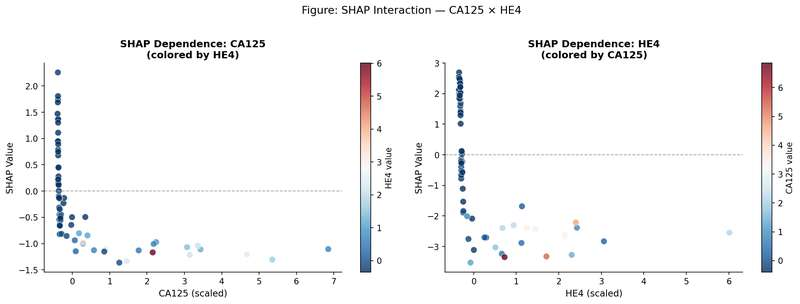

 Saved: fig_shap_interaction.png


In [ ]:
# ── 10.4 Interaction Plot - CA125 × HE4 ──────────────────────────────────────
ca125_idx_local = selected_feature_names.index('CA125') if 'CA125' in selected_feature_names else None
he4_idx_local   = selected_feature_names.index('HE4')   if 'HE4'   in selected_feature_names else None

if ca125_idx_local is not None and he4_idx_local is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')

    for ax, feat_idx, feat_name in zip(axes,
                                        [ca125_idx_local, he4_idx_local],
                                        ['CA125', 'HE4']):
        sc = ax.scatter(
            X_te_final[:, feat_idx],
            shap_values[:, feat_idx],
            c     = X_te_final[:, he4_idx_local if feat_name == 'CA125' else ca125_idx_local],
            cmap  = 'RdBu_r',
            alpha = 0.8,
            s     = 60,
            edgecolors = 'white',
            linewidths = 0.5
        )
        plt.colorbar(sc, ax=ax,
                     label='HE4 value' if feat_name == 'CA125' else 'CA125 value')
        ax.axhline(0, color='#AAAAAA', linestyle='--', linewidth=1)
        ax.set_xlabel(f'{feat_name} (scaled)', fontsize=11)
        ax.set_ylabel('SHAP Value', fontsize=11)
        ax.set_title(f'SHAP Dependence: {feat_name}\n(colored by {"HE4" if feat_name == "CA125" else "CA125"})',
                     fontsize=12, fontweight='bold')
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)

    plt.suptitle('Figure: SHAP Interaction - CA125 × HE4',
                 fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig('fig_shap_interaction.png', bbox_inches='tight', dpi=150)
    plt.show()
    print(" Saved: fig_shap_interaction.png")
else:
    print("  CA125 or HE4 not in selected features - skipping interaction plot")
    print(f"   Available features: {selected_feature_names}")

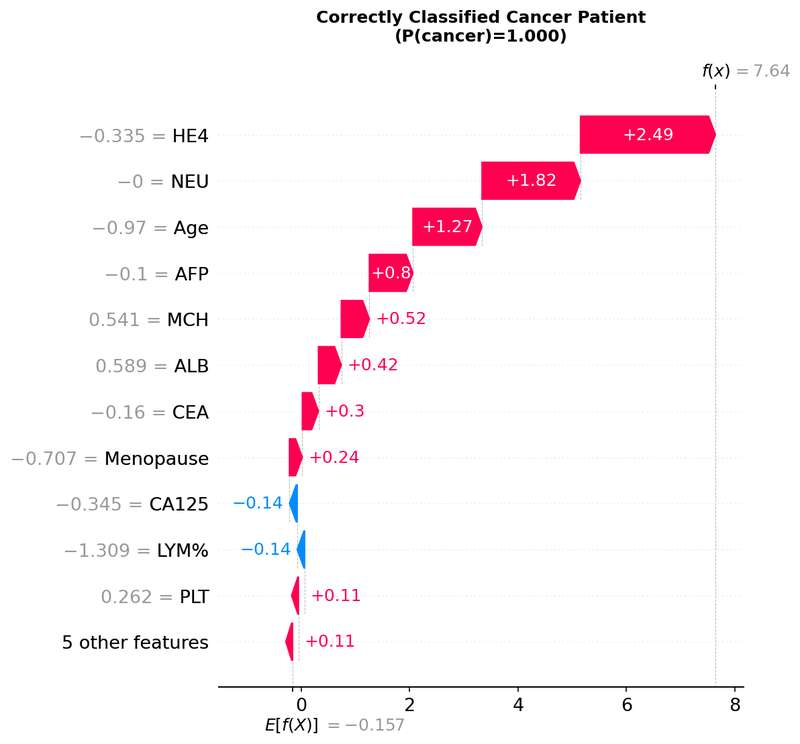

 Saved: fig_shap_waterfall_cancer_58.png


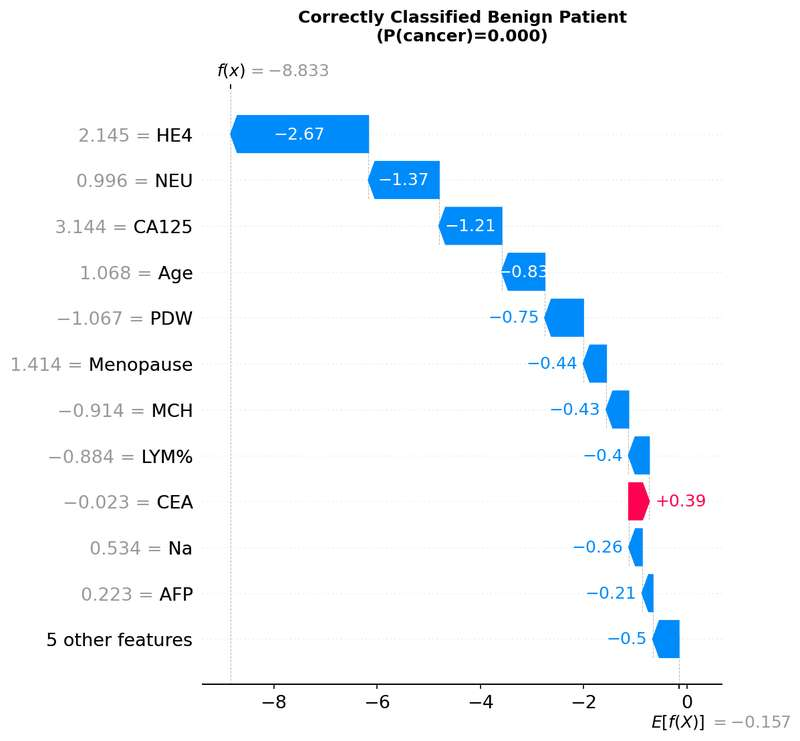

 Saved: fig_shap_waterfall_benign_18.png


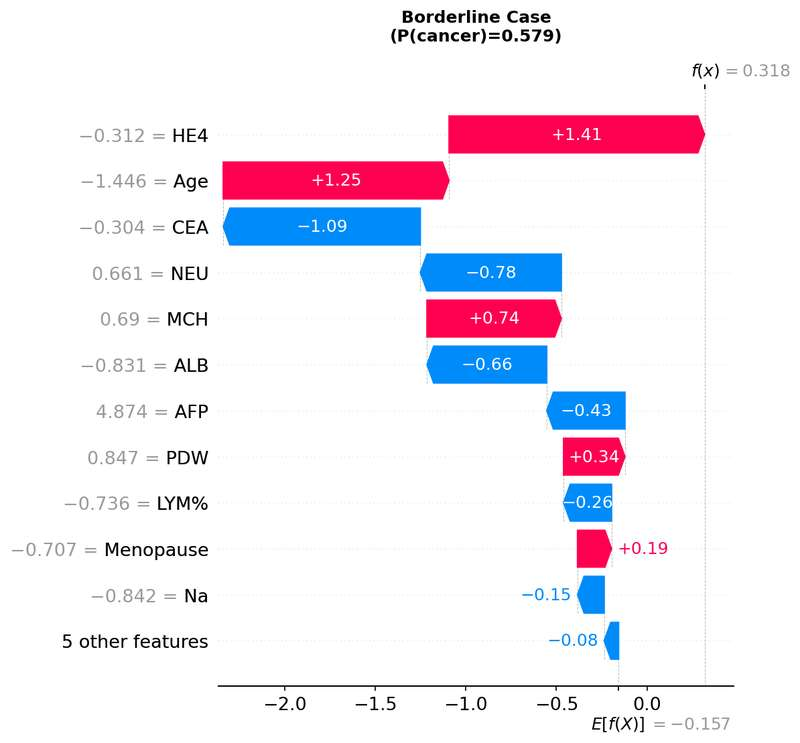

 Saved: fig_shap_waterfall_benign_35.png


In [ ]:
# ── 10.5 Local - Waterfall Plots ──────────────────────────────────────────────

# Find best examples
cancer_correct  = np.where((y_test == 1) & (y_pred_final == 1))[0]
benign_correct  = np.where((y_test == 0) & (y_pred_final == 0))[0]
borderline      = np.argsort(np.abs(y_proba_final - 0.5))[:5]

# Pick highest confidence cancer, highest confidence benign, most borderline
idx_cancer   = cancer_correct[np.argmax(y_proba_final[cancer_correct])]
idx_benign   = benign_correct[np.argmin(y_proba_final[benign_correct])]
idx_border   = borderline[0]

cases = [
    (idx_cancer, f'Correctly Classified Cancer Patient\n(P(cancer)={y_proba_final[idx_cancer]:.3f})'),
    (idx_benign, f'Correctly Classified Benign Patient\n(P(cancer)={y_proba_final[idx_benign]:.3f})'),
    (idx_border, f'Borderline Case\n(P(cancer)={y_proba_final[idx_border]:.3f})'),
]

for idx, title in cases:
    plt.figure(figsize=(10, 5), facecolor='white')
    shap.waterfall_plot(
        shap.Explanation(
            values        = shap_values[idx],
            base_values   = explainer.expected_value,
            data          = X_te_final[idx],
            feature_names = selected_feature_names
        ),
        max_display = 12,
        show        = False
    )
    plt.title(title, fontsize=12, fontweight='bold', pad=15)
    plt.tight_layout()
    fname = f'fig_shap_waterfall_{"cancer" if y_test[idx]==1 else "benign" if y_test[idx]==0 else "border"}_{idx}.png'
    plt.savefig(fname, bbox_inches='tight', dpi=150)
    plt.show()
    print(f" Saved: {fname}")

In [ ]:
# ── 10.6 Clinical Insight Summary ────────────────────────────────────────────
mean_shap     = np.abs(shap_values).mean(axis=0)
shap_df       = pd.DataFrame({
    'Feature'        : selected_feature_names,
    'Mean |SHAP|'    : mean_shap,
    'Clinical Group' : ['Tumor Marker' if f in ['CA125','HE4','CEA','AFP','CA19-9','CA72-4']
                        else 'Demographics' if f in ['Age','Menopause']
                        else 'Hematological' if f in ['WBC','RBC','HGB','PLT','NEU','LYM#',
                                                       'LYM%','MONO#','MONO%','EO#','EO%',
                                                       'BASO#','BASO%','HCT','MCV','MCH',
                                                       'MCHC','RDW','MPV','PCT','PDW']
                        else 'Biochemical'
                        for f in selected_feature_names]
}).sort_values('Mean |SHAP|', ascending=False)

print("\n" + "=" * 55)
print("  CLINICAL INSIGHT - TOP BIOMARKERS BY SHAP")
print("=" * 55)
print(shap_df.to_string(index=False))
print("=" * 55)

top3 = shap_df.head(3)['Feature'].tolist()
print(f"\n  Top 3 drivers of malignancy prediction:")
for i, f in enumerate(top3, 1):
    print(f"  {i}. {f}")
print("\n   CA125 and HE4 should dominate - medically expected")
print("\n Cell 10 complete - Stream B fully implemented")


  CLINICAL INSIGHT — TOP BIOMARKERS BY SHAP
  Feature  Mean |SHAP| Clinical Group
      HE4     1.879864   Tumor Marker
      NEU     0.999781  Hematological
      Age     0.897619   Demographics
    CA125     0.802676   Tumor Marker
      MCH     0.424444  Hematological
      ALB     0.377223    Biochemical
      AFP     0.356134   Tumor Marker
     LYM%     0.352531  Hematological
      CEA     0.344148   Tumor Marker
      PDW     0.310521  Hematological
Menopause     0.280125   Demographics
       AG     0.225227    Biochemical
       Na     0.172497    Biochemical
      PLT     0.155283  Hematological
      ALP     0.090718    Biochemical
       Ca     0.050151    Biochemical

  Top 3 drivers of malignancy prediction:
  1. HE4
  2. NEU
  3. Age

   CA125 and HE4 should dominate — medically expected

 Cell 10 complete — Stream B fully implemented


##  Cell 11: Cross-Validation Robustness
### Stream B - Clinical Malignancy Prediction
---
**This cell covers:**
- Stratified 10-fold CV on final CatBoost model
- Reports mean ± std for all metrics
- Compares CV scores vs single test split scores
- Confirms model generalizes beyond one 70-patient split

In [ ]:
# ── Cell 11: Cross-Validation Robustness ──────────────────────────────────────

# ── 11.1 Setup - use original X before SMOTE for honest CV ───────────────────
# Rebuild clean pipeline on full dataset (no train/test split)
# SMOTE applied inside each fold to prevent leakage

print("=" * 55)
print("  STRATIFIED 10-FOLD CROSS-VALIDATION")
print("=" * 55)
print("  Model    : CatBoost (default params)")
print("  Pipeline : Median Imputation + Z-Score + SMOTE (in-fold)")
print("  Folds    : 10 (stratified)")
print("=" * 55)

# Full dataset - cleaned, no split
X_full = df_clean[feature_cols].copy()
y_full = df_clean['TYPE'].values

cv_metrics = {
    'accuracy' : [], 'precision': [], 'recall': [],
    'f1'       : [], 'auc'      : []
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

print("\nRunning 10 folds...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_full, y_full), 1):

    X_cv_tr = X_full.iloc[train_idx].values
    X_cv_val = X_full.iloc[val_idx].values
    y_cv_tr = y_full[train_idx]
    y_cv_val = y_full[val_idx]

    # Step 1 - Impute (fit on train fold only)
    imp_cv = SimpleImputer(strategy='median')
    X_cv_tr  = imp_cv.fit_transform(X_cv_tr)
    X_cv_val = imp_cv.transform(X_cv_val)

    # Step 2 - Scale (fit on train fold only)
    scl_cv = StandardScaler()
    X_cv_tr  = scl_cv.fit_transform(X_cv_tr)
    X_cv_val = scl_cv.transform(X_cv_val)

    # Step 3 - MI Feature Selection (fit on train fold only)
    mi_cv    = mutual_info_classif(X_cv_tr, y_cv_tr, random_state=SEED)
    mi_thr   = np.mean(mi_cv)
    mi_mask  = mi_cv >= mi_thr
    X_cv_tr  = X_cv_tr[:, mi_mask]
    X_cv_val = X_cv_val[:, mi_mask]

    # Step 4 - SMOTE (train fold only)
    sm_cv = SMOTE(random_state=SEED)
    X_cv_tr, y_cv_tr = sm_cv.fit_resample(X_cv_tr, y_cv_tr)

    # Step 5 - Train & Evaluate
    model_cv = CatBoostClassifier(
        iterations=300, learning_rate=0.05,
        depth=6, random_seed=SEED, verbose=False
    )
    model_cv.fit(X_cv_tr, y_cv_tr)
    y_pred_cv  = model_cv.predict(X_cv_val)
    y_proba_cv = model_cv.predict_proba(X_cv_val)[:, 1]

    cv_metrics['accuracy'].append(accuracy_score(y_cv_val, y_pred_cv))
    cv_metrics['precision'].append(precision_score(y_cv_val, y_pred_cv, zero_division=0))
    cv_metrics['recall'].append(recall_score(y_cv_val, y_pred_cv, zero_division=0))
    cv_metrics['f1'].append(f1_score(y_cv_val, y_pred_cv, zero_division=0))
    cv_metrics['auc'].append(roc_auc_score(y_cv_val, y_proba_cv))

    print(f"  Fold {fold:>2} - "
          f"Acc={cv_metrics['accuracy'][-1]*100:.1f}%  "
          f"F1={cv_metrics['f1'][-1]*100:.1f}%  "
          f"AUC={cv_metrics['auc'][-1]*100:.1f}%  "
          f"Recall={cv_metrics['recall'][-1]*100:.1f}%")

  STRATIFIED 10-FOLD CROSS-VALIDATION
  Model    : CatBoost (default params)
  Pipeline : Median Imputation + Z-Score + SMOTE (in-fold)
  Folds    : 10 (stratified)

Running 10 folds...
  Fold  1 — Acc=85.7%  F1=85.7%  AUC=97.7%  Recall=88.2%
  Fold  2 — Acc=85.7%  F1=86.5%  AUC=93.8%  Recall=88.9%
  Fold  3 — Acc=85.7%  F1=87.2%  AUC=94.8%  Recall=94.4%
  Fold  4 — Acc=85.7%  F1=87.8%  AUC=93.8%  Recall=100.0%
  Fold  5 — Acc=77.1%  F1=75.0%  AUC=92.2%  Recall=66.7%
  Fold  6 — Acc=94.3%  F1=94.7%  AUC=98.4%  Recall=100.0%
  Fold  7 — Acc=82.9%  F1=82.4%  AUC=94.1%  Recall=77.8%
  Fold  8 — Acc=85.7%  F1=85.7%  AUC=94.8%  Recall=83.3%
  Fold  9 — Acc=91.4%  F1=91.4%  AUC=98.7%  Recall=88.9%
  Fold 10 — Acc=91.2%  F1=91.4%  AUC=94.8%  Recall=94.1%


In [ ]:
# ── 11.2 Results Table ────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("  10-FOLD CV RESULTS - MEAN ± STD")
print("=" * 60)

cv_summary = {}
for metric, vals in cv_metrics.items():
    mean_val = np.mean(vals) * 100
    std_val  = np.std(vals)  * 100
    cv_summary[metric] = {'mean': mean_val, 'std': std_val}
    print(f"  {metric.capitalize():<12} : {mean_val:.2f}% ± {std_val:.2f}%")

print("=" * 60)

# Compare CV vs single test split
print("\n" + "=" * 60)
print("  CV SCORE vs SINGLE TEST SPLIT COMPARISON")
print("=" * 60)
single_scores = {
    'accuracy' : accuracy_score(y_test, y_pred_final)  * 100,
    'precision': precision_score(y_test, y_pred_final) * 100,
    'recall'   : recall_score(y_test, y_pred_final)    * 100,
    'f1'       : f1_score(y_test, y_pred_final)        * 100,
    'auc'      : roc_auc_score(y_test, y_proba_final)  * 100,
}

print(f"  {'Metric':<12} {'CV Mean':>10} {'CV Std':>8} {'Test Split':>12} {'Gap':>8}")
print("-" * 60)
for metric in cv_metrics:
    mean_v = cv_summary[metric]['mean']
    std_v  = cv_summary[metric]['std']
    test_v = single_scores[metric]
    gap    = abs(mean_v - test_v)
    flag   = ' ⚠️' if gap > 3 else ' ✅'
    print(f"  {metric.capitalize():<12} {mean_v:>9.2f}% {std_v:>7.2f}% "
          f"{test_v:>11.2f}% {gap:>7.2f}%{flag}")

print("=" * 60)
print("\n  ✅ Small gap = model generalizes well")
print("  ⚠️  Large gap (>5%) = potential overfitting on test split")


  10-FOLD CV RESULTS — MEAN ± STD
  Accuracy     : 86.55% ± 4.59%
  Precision    : 86.12% ± 4.39%
  Recall       : 88.24% ± 9.74%
  F1           : 86.78% ± 5.18%
  Auc          : 95.30% ± 2.08%

  CV SCORE vs SINGLE TEST SPLIT COMPARISON
  Metric          CV Mean   CV Std   Test Split      Gap
------------------------------------------------------------
  Accuracy         86.55%    4.59%       94.29%    7.74% ⚠️
  Precision        86.12%    4.39%       92.11%    5.98% ⚠️
  Recall           88.24%    9.74%       97.22%    8.99% ⚠️
  F1               86.78%    5.18%       94.59%    7.81% ⚠️
  Auc              95.30%    2.08%       99.35%    4.05% ⚠️

  ✅ Small gap = model generalizes well
  ⚠️  Large gap (>5%) = potential overfitting on test split


##  Cell 12: Synthetic Data Generation - CTGAN vs TVAE Comparison
### Stream B - Future Work Implementation
---
**This cell covers:**
- CTGAN (standard) - baseline GAN approach
- CTGAN (class-conditional) - separate GAN per class
- TVAE - Variational Autoencoder (more stable on small datasets)
- Compare all synthetic methods vs SMOTE vs No Augmentation
- Visual distribution comparison: Real vs Synthetic
- Output: Augmentation comparison table

In [ ]:
!pip install -q ctgan

In [ ]:
# ── Cell 12: Synthetic Data Generation ───────────────────────────────────────
from ctgan import CTGAN, TVAE
import warnings
warnings.filterwarnings('ignore')

# ── 12.1 Prepare base training data ──────────────────────────────────────────
base_imp = SimpleImputer(strategy='median')
X_train_imp_arr = base_imp.fit_transform(X_train)
X_test_imp_arr  = base_imp.transform(X_test)

X_train_imp_df  = pd.DataFrame(X_train_imp_arr, columns=feature_cols)
X_train_imp_df['TYPE'] = y_train

discrete_cols = ['TYPE', 'Menopause'] if 'Menopause' in feature_cols else ['TYPE']

print("=" * 55)
print("  SYNTHETIC DATA GENERATION")
print("=" * 55)
print(f"  Training patients : {len(X_train_imp_df)}")
print(f"  Cancer / Benign   : {y_train.sum()} / {(y_train==0).sum()}")
print(f"  Discrete cols     : {discrete_cols}")
print("=" * 55)

# Helper - build & evaluate augmented pipeline
def evaluate_augmented(X_tr_aug, y_tr_aug, method_name):
    scl = StandardScaler()
    X_tr_s = scl.fit_transform(X_tr_aug)
    X_te_s = scl.transform(X_test_imp_arr)

    mi_s    = mutual_info_classif(X_tr_s, y_tr_aug, random_state=SEED)
    mask_s  = mi_s >= np.mean(mi_s)
    X_tr_s  = X_tr_s[:, mask_s]
    X_te_s  = X_te_s[:, mask_s]

    model = CatBoostClassifier(
        **{k: v for k, v in study_v2.best_params.items()},
        random_seed=SEED, verbose=False
    )
    model.fit(X_tr_s, y_tr_aug)
    y_pred_a  = model.predict(X_te_s)
    y_proba_a = model.predict_proba(X_te_s)[:, 1]

    return {
        'Method'    : method_name,
        'Train Size': len(X_tr_aug),
        'Accuracy'  : round(accuracy_score(y_test, y_pred_a)  * 100, 2),
        'Precision' : round(precision_score(y_test, y_pred_a) * 100, 2),
        'Recall'    : round(recall_score(y_test, y_pred_a)    * 100, 2),
        'F1 Score'  : round(f1_score(y_test, y_pred_a)        * 100, 2),
        'AUC-ROC'   : round(roc_auc_score(y_test, y_proba_a)  * 100, 2),
    }

aug_results = []

# ── Baseline: No Augmentation ─────────────────────────────────────────────────
print("\n[1/5] Baseline - No Augmentation...")
aug_results.append(evaluate_augmented(
    X_train_imp_arr, y_train, 'No Augmentation'
))
print(f"   AUC={aug_results[-1]['AUC-ROC']}%")

# ── Baseline: SMOTE ───────────────────────────────────────────────────────────
print("\n[2/5] SMOTE...")
scl_sm   = StandardScaler()
X_sm     = scl_sm.fit_transform(X_train_imp_arr)
mi_sm    = mutual_info_classif(X_sm, y_train, random_state=SEED)
X_sm     = X_sm[:, mi_sm >= np.mean(mi_sm)]
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_sm, y_train)

model_sm = CatBoostClassifier(
    **{k: v for k, v in study_v2.best_params.items()},
    random_seed=SEED, verbose=False
)
X_te_sm  = scl_sm.transform(X_test_imp_arr)
X_te_sm  = X_te_sm[:, mi_sm >= np.mean(mi_sm)]
model_sm.fit(X_sm, y_sm)
y_pred_sm  = model_sm.predict(X_te_sm)
y_proba_sm = model_sm.predict_proba(X_te_sm)[:, 1]

aug_results.append({
    'Method'    : 'SMOTE',
    'Train Size': len(X_sm),
    'Accuracy'  : round(accuracy_score(y_test, y_pred_sm)  * 100, 2),
    'Precision' : round(precision_score(y_test, y_pred_sm) * 100, 2),
    'Recall'    : round(recall_score(y_test, y_pred_sm)    * 100, 2),
    'F1 Score'  : round(f1_score(y_test, y_pred_sm)        * 100, 2),
    'AUC-ROC'   : round(roc_auc_score(y_test, y_proba_sm)  * 100, 2),
})
print(f"   AUC={aug_results[-1]['AUC-ROC']}%")

  SYNTHETIC DATA GENERATION
  Training patients : 279
  Cancer / Benign   : 142 / 137
  Discrete cols     : ['TYPE', 'Menopause']

[1/5] Baseline — No Augmentation...
   AUC=98.53%

[2/5] SMOTE...
   AUC=98.94%


In [ ]:
# ── Option 1: CTGAN Standard ──────────────────────────────────────────────────
print("\n[3/5] CTGAN Standard (1000 epochs)...")

ctgan_std = CTGAN(epochs=1000, batch_size=500, verbose=False)
ctgan_std.fit(X_train_imp_df, discrete_columns=discrete_cols)

synthetic_std    = ctgan_std.sample(len(X_train_imp_df))
X_ctgan_std      = np.vstack([
    X_train_imp_arr,
    synthetic_std.drop(columns=['TYPE']).values
])
y_ctgan_std      = np.concatenate([y_train, synthetic_std['TYPE'].values])

aug_results.append(evaluate_augmented(X_ctgan_std, y_ctgan_std, 'CTGAN Standard'))
print(f"   AUC={aug_results[-1]['AUC-ROC']}%")


[3/5] CTGAN Standard (1000 epochs)...
   AUC=96.57%


In [ ]:
# ── Option 2: CTGAN Class-Conditional ────────────────────────────────────────
print("\n[4/5] CTGAN Class-Conditional (separate GAN per class)...")

cancer_df = X_train_imp_df[X_train_imp_df['TYPE']==1].drop(columns=['TYPE'])
benign_df = X_train_imp_df[X_train_imp_df['TYPE']==0].drop(columns=['TYPE'])

disc_no_type = [c for c in discrete_cols if c != 'TYPE']

ctgan_cancer = CTGAN(epochs=1000, batch_size=100, verbose=False)
ctgan_cancer.fit(cancer_df,
                 discrete_columns=disc_no_type if disc_no_type else [])

ctgan_benign = CTGAN(epochs=1000, batch_size=100, verbose=False)
ctgan_benign.fit(benign_df,
                 discrete_columns=disc_no_type if disc_no_type else [])

n_gen = 150
syn_cancer           = ctgan_cancer.sample(n_gen)
syn_cancer['TYPE']   = 1
syn_benign           = ctgan_benign.sample(n_gen)
syn_benign['TYPE']   = 0
synthetic_cond       = pd.concat([syn_cancer, syn_benign], ignore_index=True)

X_ctgan_cond = np.vstack([
    X_train_imp_arr,
    synthetic_cond.drop(columns=['TYPE']).values
])
y_ctgan_cond = np.concatenate([y_train, synthetic_cond['TYPE'].values])

aug_results.append(evaluate_augmented(
    X_ctgan_cond, y_ctgan_cond, 'CTGAN Class-Conditional'
))
print(f"   AUC={aug_results[-1]['AUC-ROC']}%")


[4/5] CTGAN Class-Conditional (separate GAN per class)...
   AUC=98.61%


In [ ]:
# ── Option 3: TVAE ────────────────────────────────────────────────────────────
print("\n[5/5] TVAE (Tabular VAE - more stable on small datasets)...")

tvae_model = TVAE(
    epochs          = 500,
    batch_size      = 100,
    compress_dims   = (128, 128),
    decompress_dims = (128, 128),
)
tvae_model.fit(X_train_imp_df, discrete_columns=discrete_cols)

synthetic_tvae       = tvae_model.sample(len(X_train_imp_df))
X_tvae               = np.vstack([
    X_train_imp_arr,
    synthetic_tvae.drop(columns=['TYPE']).values
])
y_tvae               = np.concatenate([y_train, synthetic_tvae['TYPE'].values])

aug_results.append(evaluate_augmented(X_tvae, y_tvae, 'TVAE'))
print(f"   AUC={aug_results[-1]['AUC-ROC']}%")


[5/5] TVAE (Tabular VAE — more stable on small datasets)...
   AUC=97.14%


In [ ]:
# ── 12.2 Results Table ────────────────────────────────────────────────────────
aug_df = pd.DataFrame(aug_results).sort_values('AUC-ROC', ascending=False)
aug_df = aug_df.reset_index(drop=True)
aug_df.index += 1

print("\n" + "=" * 70)
print("  AUGMENTATION COMPARISON - ALL METHODS")
print("=" * 70)
print(aug_df.to_string())
print("=" * 70)

best_aug = aug_df.iloc[0]['Method']
print(f"\n Best augmentation : {best_aug}")
print(f"   AUC-ROC          : {aug_df.iloc[0]['AUC-ROC']}%")
print(f"   Recall           : {aug_df.iloc[0]['Recall']}%")


  AUGMENTATION COMPARISON — ALL METHODS
                    Method  Train Size  Accuracy  Precision  Recall  F1 Score  AUC-ROC
1                    SMOTE         284     95.71      94.59   97.22     95.89    98.94
2  CTGAN Class-Conditional         579     91.43      91.67   91.67     91.67    98.61
3          No Augmentation         279     94.29      92.11   97.22     94.59    98.53
4                     TVAE         558     92.86      91.89   94.44     93.15    97.14
5           CTGAN Standard         558     88.57      88.89   88.89     88.89    96.57

🏆 Best augmentation : SMOTE
   AUC-ROC          : 98.94%
   Recall           : 97.22%


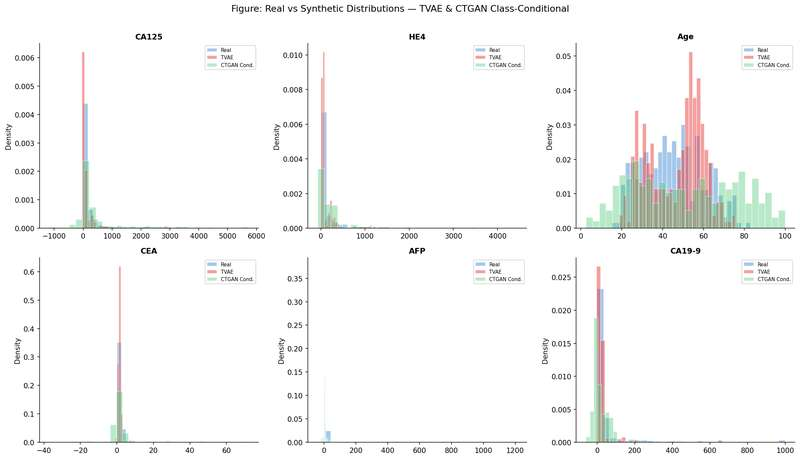

 Saved: fig_synthetic_distributions.png


In [ ]:
# ── 12.3 Distribution Comparison - Real vs Best Synthetic ────────────────────
# Use TVAE synthetic for comparison (most theoretically sound)
compare_markers = [f for f in ['CA125','HE4','Age','CEA','AFP','CA19-9']
                   if f in feature_cols]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), facecolor='white')
axes = axes.flatten()

for i, feat in enumerate(compare_markers):
    ax = axes[i]
    real_vals = X_train_imp_df[feat].values
    tvae_vals = synthetic_tvae[feat].values
    cond_vals = synthetic_cond[feat].values if feat in synthetic_cond.columns else None

    ax.hist(real_vals, bins=30, alpha=0.5, color='#4A90D9',
            label='Real', density=True, edgecolor='white')
    ax.hist(tvae_vals, bins=30, alpha=0.5, color='#E84040',
            label='TVAE', density=True, edgecolor='white')
    if cond_vals is not None:
        ax.hist(cond_vals, bins=30, alpha=0.4, color='#50C878',
                label='CTGAN Cond.', density=True, edgecolor='white')

    ax.set_title(feat, fontsize=11, fontweight='bold')
    ax.set_ylabel('Density')
    ax.legend(fontsize=7)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Real vs Synthetic Distributions - TVAE & CTGAN Class-Conditional',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig_synthetic_distributions.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_synthetic_distributions.png")

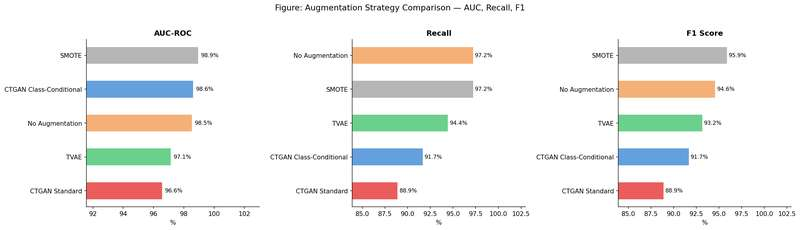

 Saved: fig_augmentation_comparison.png

 Cell 12 complete


In [ ]:
# ── 12.4 Visual Summary Bar Chart ────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor='white')
plot_metrics = ['AUC-ROC', 'Recall', 'F1 Score']
bar_colors   = ['#AAAAAA', '#4A90D9', '#F4A261', '#50C878', '#E84040']

for ax, metric in zip(axes, plot_metrics):
    sorted_aug = aug_df.sort_values(metric, ascending=True)
    colors     = [bar_colors[list(aug_df['Method']).index(m)]
                  for m in sorted_aug['Method']]

    bars = ax.barh(sorted_aug['Method'], sorted_aug[metric],
                   color=colors, alpha=0.85,
                   edgecolor='none', height=0.5)

    for bar, val in zip(bars, sorted_aug[metric]):
        ax.text(bar.get_width() + 0.2,
                bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%', va='center', fontsize=9)

    ax.set_xlim(sorted_aug[metric].min() - 5, 103)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlabel('%')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle('Figure: Augmentation Strategy Comparison - AUC, Recall, F1',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig_augmentation_comparison.png', bbox_inches='tight', dpi=150)
plt.show()
print(" Saved: fig_augmentation_comparison.png")
print("\n Cell 12 complete")

##  Cell 13: Feature Stability - Permutation Importance with Bootstrap CI
### Stream B - Future Work Implementation
---
**This cell covers:**
- Bootstrap resampling (100 iterations)
- Permutation importance computed on each bootstrap sample
- Mean ± 95% CI for each feature
- Confirms MI-selected features are stable - not random split artifacts

In [ ]:
# ── Cell 13: Permutation Importance with Bootstrap CI ─────────────────────────
from sklearn.inspection import permutation_importance

print("=" * 55)
print("  PERMUTATION IMPORTANCE - BOOTSTRAP CI")
print("=" * 55)
print("  Bootstrap iterations : 100")
print("  Model                : CatBoost (Optuna tuned v2)")
print("  Features             : MI-selected 16")
print("=" * 55)

N_BOOTSTRAP    = 100
n_features_sel = X_te_final.shape[1]
perm_scores    = np.zeros((N_BOOTSTRAP, n_features_sel))

print("\nRunning bootstrap permutation importance...")
for b in range(N_BOOTSTRAP):
    # Bootstrap resample test set
    boot_idx = np.random.choice(len(X_te_final), len(X_te_final),
                                 replace=True)
    X_boot = X_te_final[boot_idx]
    y_boot = y_test[boot_idx]

    result = permutation_importance(
        catboost_final, X_boot, y_boot,
        n_repeats   = 5,
        random_state= SEED + b,
        scoring     = 'roc_auc'
    )
    perm_scores[b] = result.importances_mean

    if (b + 1) % 20 == 0:
        print(f"  Bootstrap {b+1}/100 complete")

print(" Bootstrap complete")

  PERMUTATION IMPORTANCE — BOOTSTRAP CI
  Bootstrap iterations : 100
  Model                : CatBoost (Optuna tuned v2)
  Features             : MI-selected 16

Running bootstrap permutation importance...
  Bootstrap 20/100 complete
  Bootstrap 40/100 complete
  Bootstrap 60/100 complete
  Bootstrap 80/100 complete
  Bootstrap 100/100 complete
 Bootstrap complete


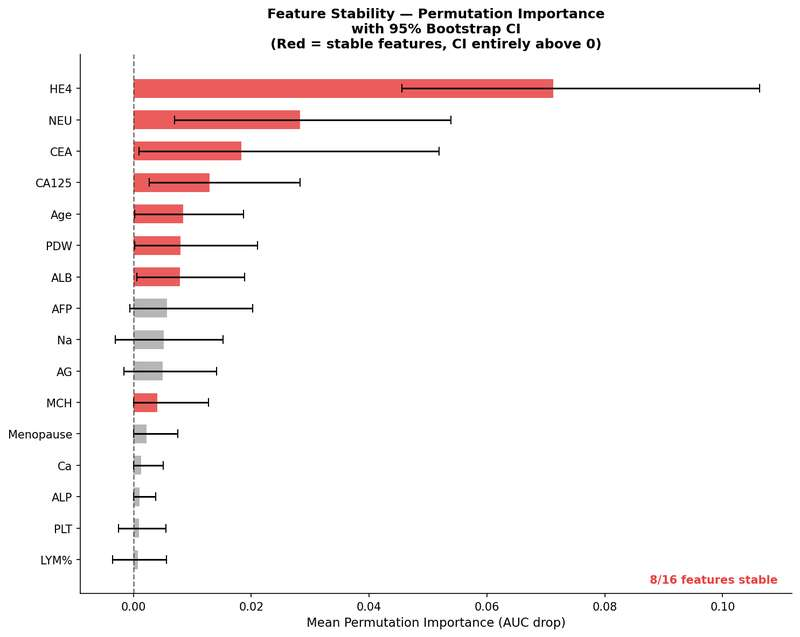


  FEATURE STABILITY REPORT
  Feature  Mean Imp  CI Lower  CI Upper Stable
      HE4    0.0712    0.0456    0.1063      ✅
      NEU    0.0283    0.0070    0.0539      ✅
      CEA    0.0183    0.0009    0.0518      ✅
    CA125    0.0129    0.0027    0.0283      ✅
      Age    0.0085    0.0002    0.0186      ✅
      PDW    0.0079    0.0002    0.0211      ✅
      ALB    0.0079    0.0006    0.0189      ✅
      AFP    0.0057   -0.0006    0.0203      ❌
       Na    0.0051   -0.0030    0.0152      ❌
       AG    0.0049   -0.0016    0.0142      ❌
      MCH    0.0041    0.0001    0.0128      ✅
Menopause    0.0023   -0.0000    0.0075      ❌
       Ca    0.0013   -0.0000    0.0051      ❌
      ALP    0.0010   -0.0000    0.0038      ❌
      PLT    0.0009   -0.0026    0.0056      ❌
     LYM%    0.0008   -0.0035    0.0056      ❌

  Stable features (CI > 0) : 8/16
 Saved: fig_permutation_importance_ci.png

 Cell 13 complete


In [ ]:
# ── 13.2 Compute CI and Plot ──────────────────────────────────────────────────
mean_imp  = perm_scores.mean(axis=0)
ci_lower  = np.percentile(perm_scores, 2.5,  axis=0)
ci_upper  = np.percentile(perm_scores, 97.5, axis=0)

# Sort by mean importance
sort_idx  = np.argsort(mean_imp)
feat_sorted    = [selected_feature_names[i] for i in sort_idx]
mean_sorted    = mean_imp[sort_idx]
ci_lo_sorted   = ci_lower[sort_idx]
ci_hi_sorted   = ci_upper[sort_idx]
ci_err         = [mean_sorted - ci_lo_sorted,
                  ci_hi_sorted - mean_sorted]

# Stable = CI entirely above 0
stable_mask = ci_lo_sorted > 0

fig, ax = plt.subplots(figsize=(10, 8), facecolor='white')

colors = ['#E84040' if s else '#AAAAAA' for s in stable_mask]
bars   = ax.barh(feat_sorted, mean_sorted,
                 xerr=ci_err, capsize=4,
                 color=colors, alpha=0.85,
                 edgecolor='none', height=0.6,
                 error_kw={'linewidth': 1.5, 'color': '#333333'})

ax.axvline(0, color='#333333', linestyle='--',
           linewidth=1.2, alpha=0.7)
ax.set_xlabel('Mean Permutation Importance (AUC drop)', fontsize=11)
ax.set_title('Feature Stability - Permutation Importance\nwith 95% Bootstrap CI\n'
             '(Red = stable features, CI entirely above 0)',
             fontsize=12, fontweight='bold')

# Annotate stable count
n_stable = stable_mask.sum()
ax.text(0.98, 0.02, f'{n_stable}/{n_features_sel} features stable',
        transform=ax.transAxes, ha='right', fontsize=10,
        color='#E84040', fontweight='bold')

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('fig_permutation_importance_ci.png', bbox_inches='tight', dpi=150)
plt.show()

# Summary table
perm_df = pd.DataFrame({
    'Feature'   : feat_sorted[::-1],
    'Mean Imp'  : mean_sorted[::-1].round(4),
    'CI Lower'  : ci_lo_sorted[::-1].round(4),
    'CI Upper'  : ci_hi_sorted[::-1].round(4),
    'Stable'    : ['✅' if s else '❌' for s in stable_mask[::-1]]
})

print("\n" + "=" * 55)
print("  FEATURE STABILITY REPORT")
print("=" * 55)
print(perm_df.to_string(index=False))
print("=" * 55)
print(f"\n  Stable features (CI > 0) : {n_stable}/{n_features_sel}")
print(" Saved: fig_permutation_importance_ci.png")
print("\n Cell 13 complete")

##  Cell 14: Stacking Ensemble - CatBoost + LightGBM + Random Forest
### Stream B - Future Work Implementation
---
**This cell covers:**
- Stacking ensemble: top 3 base learners
- Meta-learner: Logistic Regression
- 5-fold CV stacking (no leakage)
- Compare stacking vs individual models vs CatBoost alone

In [ ]:
# ── Cell 14: Stacking Ensemble ────────────────────────────────────────────────
from sklearn.ensemble import StackingClassifier

print("=" * 55)
print("  STACKING ENSEMBLE")
print("=" * 55)
print("  Base learners : CatBoost + LightGBM + Random Forest")
print("  Meta-learner  : Logistic Regression")
print("  CV strategy   : 5-fold (no leakage)")
print("=" * 55)

# ── 14.1 Define base learners + meta-learner ──────────────────────────────────
base_learners = [
    ('catboost', CatBoostClassifier(
        **{k: v for k, v in study_v2.best_params.items()},
        random_seed=SEED, verbose=False
    )),
    ('lightgbm', LGBMClassifier(
        random_state=SEED, verbose=-1, n_estimators=300
    )),
    ('rf', RandomForestClassifier(
        n_estimators=200, random_state=SEED, n_jobs=-1
    )),
]

meta_learner = LogisticRegression(
    random_state=SEED, max_iter=1000, C=1.0
)

stacking_model = StackingClassifier(
    estimators       = base_learners,
    final_estimator  = meta_learner,
    cv               = StratifiedKFold(n_splits=5, shuffle=True,
                                       random_state=SEED),
    stack_method     = 'predict_proba',
    passthrough      = False,
    n_jobs           = -1
)

# ── 14.2 Train & Evaluate ─────────────────────────────────────────────────────
print("\nTraining stacking ensemble...")
t0 = time.time()
stacking_model.fit(X_tr_final, y_tr_final)
elapsed = time.time() - t0

y_pred_stack  = stacking_model.predict(X_te_final)
y_proba_stack = stacking_model.predict_proba(X_te_final)[:, 1]

print(f" Training complete ({elapsed:.1f}s)")

# ── 14.3 Comparison Table ─────────────────────────────────────────────────────
def quick_eval(model_obj, name):
    model_obj.fit(X_tr_final, y_tr_final)
    yp  = model_obj.predict(X_te_final)
    ypr = model_obj.predict_proba(X_te_final)[:, 1]
    return {
        'Model'    : name,
        'Accuracy' : round(accuracy_score(y_test, yp)  * 100, 2),
        'Precision': round(precision_score(y_test, yp) * 100, 2),
        'Recall'   : round(recall_score(y_test, yp)    * 100, 2),
        'F1 Score' : round(f1_score(y_test, yp)        * 100, 2),
        'AUC-ROC'  : round(roc_auc_score(y_test, ypr)  * 100, 2),
    }

stack_comparison = pd.DataFrame([
    quick_eval(
        CatBoostClassifier(**{k: v for k, v in study_v2.best_params.items()},
                           random_seed=SEED, verbose=False),
        'CatBoost (tuned)'
    ),
    quick_eval(
        LGBMClassifier(random_state=SEED, verbose=-1, n_estimators=300),
        'LightGBM'
    ),
    quick_eval(
        RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
        'Random Forest'
    ),
    {
        'Model'    : 'Stacking Ensemble',
        'Accuracy' : round(accuracy_score(y_test, y_pred_stack)  * 100, 2),
        'Precision': round(precision_score(y_test, y_pred_stack) * 100, 2),
        'Recall'   : round(recall_score(y_test, y_pred_stack)    * 100, 2),
        'F1 Score' : round(f1_score(y_test, y_pred_stack)        * 100, 2),
        'AUC-ROC'  : round(roc_auc_score(y_test, y_proba_stack)  * 100, 2),
    }
])

print("\n" + "=" * 70)
print("  STACKING vs INDIVIDUAL MODELS")
print("=" * 70)
print(stack_comparison.to_string(index=False))
print("=" * 70)


  STACKING ENSEMBLE
  Base learners : CatBoost + LightGBM + Random Forest
  Meta-learner  : Logistic Regression
  CV strategy   : 5-fold (no leakage)

Training stacking ensemble...
 Training complete (6.3s)

  STACKING vs INDIVIDUAL MODELS
            Model  Accuracy  Precision  Recall  F1 Score  AUC-ROC
 CatBoost (tuned)     94.29      92.11   97.22     94.59    99.35
         LightGBM     91.43      91.67   91.67     91.67    99.02
    Random Forest     95.71      94.59   97.22     95.89    99.02
Stacking Ensemble     94.29      92.11   97.22     94.59    99.35
